# When Trading Dries Up: a liquidity signal for a long-only fund

*Heavy steps ran on BYU's supercomputer with the same code shown here, and their saved outputs are shown under those
cells. Everything else runs in this notebook from the saved results.*

When trading in a stock suddenly dries up, the stock keeps falling for months: about 3% behind similar stocks over the next
year, beyond anything the fund's six existing scores capture. We turn this into a Grinold–Kahn alpha and trade it with the
fund's optimizer. Rebalanced daily, the long-only portfolio earns +0.19% a year in 2011–2018 and +0.51% a year (information
ratio 1.05) in 2019–2024, years we held back and ran only once. The effect is real but small, so it belongs as one input to
the fund's alpha.

## 1. The idea

**Two kinds of investors.** Most investors (mutual funds facing daily redemptions, institutions that size positions by
trading volume, active traders) want stocks they can buy and sell quickly and cheaply. A much smaller group with long
horizons will hold illiquid stocks, but only at a lower price, which earns them a slightly higher expected return (Amihud and
Mendelson 1986). Liquid stocks are held by the many, illiquid stocks by the patient few.

**A collapse forces a hand-off.** When trading in a stock suddenly collapses, it no longer suits the investors who own it, and
it has to pass to the patient group. Sellers can exit only a little at a time, because volume has dried up, and the few
patient buyers need a slightly lower price for each sale. The price walks down step by step until the stock is held by
investors content at the new, lower price.

**Why the drift is not traded away.** Anyone who saw the decline coming would short the stock, but shorting small, illiquid
stocks is expensive and often impossible, so the decline is predictable and persists (Bali et al. 2014).

**Predictions** (about the *change* in liquidity, not its level): (1) lower returns than similar stocks whose liquidity did not
collapse; (2) a gradual decline, strongest at first; (3) strongest in small stocks, where patient buyers are scarcest;
(4) driven by the fall in trading volume, which is what slows the exit; (5) stocks that are *already* illiquid earn slightly
more, the patient holders' reward.

**The question for the fund.** The fund is long-only and already trades six scores (idiosyncratic volatility, momentum,
reversal, Barra momentum, beta, Barra reversal). Does the signal add new information, and can a fund that can only hold
*less* of a stock than the benchmark make money from it?

## 2. Setup

In [1]:
import datetime as dt, json, math, os, time
from pathlib import Path

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import sf_quant.data as sfd
import sf_quant.performance as sfp
from IPython.display import Image, display
from sf_quant.data.covariance_matrix import construct_factor_model_components
from sf_quant.optimizer import LongOnly, ZeroBeta, ZeroInvestment
from sf_quant.optimizer.optimizers import _construct_constraints

from liquidity_collapse import style
from liquidity_collapse.config import CFG, FUND_SCORES, OUTPUT, PANEL, RESULTS, SIGNALS, YEARS, connect
from liquidity_collapse.evaluate import nw_t

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
connect()
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_hide_column_data_types(True)
pl.Config.set_float_precision(2)

Settings from `config.toml` used below: the event definition and the optimizer.

In [2]:
print({k: CFG["event"][k] for k in ("flag_share", "refractory", "bucket_edges", "stop_t")})
print({k: CFG["optimizer"][k] for k in ("start", "end", "target_risk")}, "| held back:", CFG["window"]["holdout_start"], "to", CFG["window"]["holdout_end"])

{'flag_share': 0.05, 'refractory': 21, 'bucket_edges': [21, 63, 126, 252, 378, 504], 'stop_t': 0.0}
{'start': datetime.date(2011, 1, 3), 'end': datetime.date(2018, 12, 31), 'target_risk': 0.05} | held back: 2019-01-01 to 2024-12-31


## 3. The signal

**Liquidity shock.** Amihud illiquidity is the price move per dollar traded, $|r|/(P\cdot V)$, averaged over the last 21
trading days. The shock compares it with the stock's own average over the previous year, so a very low value means trading
just dried up *for that stock*. **Removing what the fund knows:** each day the shock is regressed across stocks on the fund's
six scores and the residual is standardized to a $Z$-score, so the signal only gets credit for new information.

In [3]:
def features(columns: list[str], years=YEARS) -> pl.LazyFrame:
    return pl.scan_parquet([FEATURES / f"features_{y}.parquet" for y in years]).select(columns)


O = CFG["optimizer"]


HOLDOUT = os.environ.get("LAB_HOLDOUT") == "1"


END = CFG["window"]["holdout_end"] if HOLDOUT else O["end"]


OPT = OUTPUT / ("optimizer_holdout" if HOLDOUT else "optimizer")


DAILY = OPT / "daily_signal.parquet"


SMOOTHED = OPT / "smoothed.parquet"


def guard(date_: dt.date) -> None:
    if date_ > END:
        raise RuntimeError(f"refusing to read data after {END}: {date_}")


def raw_shock(barrids: pl.Series) -> pl.DataFrame:
    frames = []
    for year in range(2004, END.year + 1):
        lo, hi = dt.date(year, 1, 1), min(dt.date(year, 12, 31), END)
        guard(hi)
        d = sfd.load_assets(lo, hi, ["date", "barrid", "return", "price", "daily_volume"], in_universe=False)
        frames.append(
            d.filter(pl.col("barrid").is_in(barrids.implode())).select(
                "date", "barrid",
                pl.when((pl.col("daily_volume") > 0) & (pl.col("price") > 0) & pl.col("return").is_not_null())
                .then((pl.col("return") / 100).abs() / (pl.col("price") * pl.col("daily_volume"))).alias("x"),
            )
        )
        print(f"raw: loaded {year}", flush=True)
    d = pl.concat(frames).sort("barrid", "date").with_columns(
        L=pl.col("x").rolling_mean(21, min_samples=15).over("barrid").log()
    ).with_columns(pl.when(pl.col("L").is_finite()).then(pl.col("L")).alias("L"))
    shifted = [pl.col("L").shift(21 * k).over("barrid") for k in range(1, 13)]
    d = d.with_columns(
        n=pl.sum_horizontal([s.is_not_null().cast(pl.Int32) for s in shifted]),
        total=pl.sum_horizontal(shifted),
    )
    return d.select("date", "barrid", pl.when(pl.col("n") >= 9).then(-(pl.col("L") - pl.col("total") / pl.col("n"))).alias("raw")).drop_nulls()


def build() -> None:
    """Writes DAILY (date, barrid, raw, z) for eligible stock-days 2005-END."""
    OPT.mkdir(parents=True, exist_ok=True)
    eligible = (
        features(["date", "barrid", "eligible"], years=range(2005, END.year + 1))
        .filter(pl.col("eligible"), pl.col("date") <= END).select("date", "barrid").collect()
    )
    data = raw_shock(eligible["barrid"].unique()).join(eligible, on=["date", "barrid"])
    scores = []
    for year in range(2005, END.year + 1):
        lo, hi = dt.date(year, 1, 1), min(dt.date(year, 12, 31), END)
        s = sfd.load_scores(lo, hi, FUND_SCORES)
        scores.append(s.pivot(on="signal_name", index=["date", "barrid"], values="score"))
        print(f"scores: loaded {year}", flush=True)
    data = data.join(pl.concat(scores, how="diagonal_relaxed"), on=["date", "barrid"], how="inner").drop_nulls(
        ["raw", *FUND_SCORES]
    ).filter(pl.all_horizontal([pl.col(c).is_finite() for c in ["raw", *FUND_SCORES]]))

    def one(day: pl.DataFrame) -> pl.DataFrame:
        x = np.column_stack([np.ones(day.height), day.select(FUND_SCORES).to_numpy()])
        y = day["raw"].to_numpy()
        r = y - x @ np.linalg.lstsq(x, y, rcond=None)[0]
        return day.select("date", "barrid", "raw").with_columns(z=pl.Series((r - r.mean()) / r.std()))

    out = data.group_by("date", maintain_order=True).map_groups(one).sort("date", "barrid")
    out.write_parquet(DAILY)
    print({"rows": out.height, "days": out["date"].n_unique(), "first": out["date"].min(), "last": out["date"].max()}, flush=True)


def smooth() -> pl.DataFrame:
    """EWMA of z for every half-life, on a full day x stock grid so absent days decay toward 0."""
    z = pl.read_parquet(DAILY, columns=["date", "barrid", "z"]).filter(pl.col("date") >= O["history_start"])
    days = z["date"].unique().sort()
    names = z["barrid"].unique().sort()
    di = pl.DataFrame({"date": days, "i": np.arange(len(days))})
    bi = pl.DataFrame({"barrid": names, "j": np.arange(len(names))})
    idx = z.join(di, on="date").join(bi, on="barrid")
    grid = np.zeros((len(days), len(names)))
    grid[idx["i"].to_numpy(), idx["j"].to_numpy()] = idx["z"].to_numpy()
    out = idx.select("date", "barrid", "i", "j")
    for h in O["half_lives"]:
        lam = 0.0 if h == 0 else 0.5 ** (1 / h)  # h = 0: no smoothing
        s, smoothed = np.zeros(len(names)), np.empty_like(grid)
        for t in range(len(days)):
            s = lam * s + (1 - lam) * grid[t]
            smoothed[t] = s
        out = out.with_columns(pl.Series(f"s{h}", smoothed[idx["i"].to_numpy(), idx["j"].to_numpy()]))
    out = out.drop("i", "j").sort("date", "barrid")
    out.write_parquet(SMOOTHED)
    return out

In [4]:
build()
smooth()

raw: loaded 2004
raw: loaded 2005
raw: loaded 2006
raw: loaded 2007
raw: loaded 2008
raw: loaded 2009
raw: loaded 2010
raw: loaded 2011
raw: loaded 2012
raw: loaded 2013
raw: loaded 2014
raw: loaded 2015
raw: loaded 2016
raw: loaded 2017
raw: loaded 2018
scores: loaded 2005
scores: loaded 2006
scores: loaded 2007
scores: loaded 2008
scores: loaded 2009
scores: loaded 2010
scores: loaded 2011
scores: loaded 2012
scores: loaded 2013
scores: loaded 2014
scores: loaded 2015
scores: loaded 2016
scores: loaded 2017
scores: loaded 2018
{'rows': 9294571, 'days': 3523, 'first': datetime.date(2005, 1, 3), 'last': datetime.date(2018, 12, 31)}


**Events.** A stock has an event when its $Z$ enters the worst 5% after 21 trading days outside it. Its age is the number of
trading days since the event; a new event restarts the clock. Everything is measured against **similar stocks**: same day,
same size fifth, same fifth of illiquidity three months earlier, no recent event. Returns are abnormal returns: the part of
each stock's return not explained by the market and Barra's industry and style factors (Barra's specific return).

In [5]:
E = CFG["event"]


REFRACTORY = E["refractory"]


FLAG_SHARE = E["flag_share"]


STOP_T = E["stop_t"]


EDGES = E["bucket_edges"]


BUCKETS = [(lo + 1, hi) for lo, hi in zip([0, *EDGES[:-1]], EDGES)]


COLUMN = "s0"


EVENT_PARAMS = OPT / "event_params.json"


GROUPS = ("rest", "large")


def events(scores: pl.DataFrame, column: str, share: float) -> pl.DataFrame:
    """scores: date, barrid, <column>, market_cap (one row per scored stock-day).
    Returns date, barrid, event, control (unflagged now and in the prior REFRACTORY days) and
    group (0 rest, 1 largest size fifth) on every row."""
    return (
        scores.drop_nulls(column)
        .with_columns(
            flag=(pl.col(column).rank("ordinal").over("date") <= (pl.len().over("date") * share).ceil()).cast(pl.Int8),
            group=(pl.col("market_cap").rank().over("date") > 0.8 * pl.len().over("date")).fill_null(False).cast(pl.Int8),
        )
        .sort("barrid", "date")
        .with_columns(recent=pl.col("flag").shift(1).rolling_max(REFRACTORY, min_samples=1).over("barrid").fill_null(0))
        .select("date", "barrid",
                ((pl.col("flag") == 1) & (pl.col("recent") == 0)).alias("event"),
                ((pl.col("flag") == 0) & (pl.col("recent") == 0)).alias("control"), "group",
                *(["vol"] if "vol" in scores.columns else []))
    )


def ages(rows: pl.DataFrame, ev: pl.DataFrame, day_index: dict) -> pl.DataFrame:
    """rows: date, barrid (+ anything). Adds age = trading days since the stock's latest event on or
    before that date (0 = event that day, null = none yet) and event_group (size group at that event).
    A return earned on day t belongs to age(t) >= 1; weights for day D use age(signal day) + 1."""
    idx = pl.DataFrame({"date": list(day_index), "t": list(day_index.values())})
    e = ev.filter("event").join(idx, on="date").select("barrid", "t", pl.col("t").alias("e"), pl.col("group").alias("event_group"),
                                                        *([pl.col("vol").alias("event_vol")] if "vol" in ev.columns else []))
    r = pl.concat([
        rows.join(idx, on="date").with_columns(pl.lit(0, pl.Int8).alias("_src")),
        e.with_columns(pl.lit(1, pl.Int8).alias("_src")),
    ], how="diagonal_relaxed").sort("barrid", "t", "_src", descending=[False, False, True])  # an event sorts before its day's row
    r = r.with_columns(pl.col("e").forward_fill().over("barrid"), pl.col("event_group").forward_fill().over("barrid"),
                       *([pl.col("event_vol").forward_fill().over("barrid")] if "event_vol" in e.columns else []))
    return r.filter(pl.col("_src") == 0).with_columns(age=pl.col("t") - pl.col("e")).drop("e", "_src", "t")


def panel() -> pl.DataFrame:
    """Scored, eligible stock-days 2006-END with specific return, size, pre-shock illiquidity,
    past returns, next-month target and the unsmoothed score."""
    guard(END)
    f = (
        features(["date", "barrid", "s", "eligible", "market_cap", "amihud63", "target21", "ivol63"], years=range(2005, END.year + 1))
        .filter(pl.col("date") <= END).collect().sort("barrid", "date")
        .with_columns(ls=pl.col("s").fill_null(0.0).log1p())
        .with_columns(c=pl.col("ls").cum_sum().over("barrid"))
        .with_columns(
            level=pl.col("amihud63").shift(63).over("barrid"),
            mom=pl.col("c").shift(21).over("barrid") - pl.col("c").shift(252).over("barrid"),
            ltr=pl.col("c").shift(252).over("barrid") - pl.col("c").shift(756).over("barrid"),
        )
        .filter(pl.col("eligible"), pl.col("date") >= dt.date(2006, 1, 1))
        .select("date", "barrid", "s", "market_cap", "level", "mom", "ltr", "target21", pl.col("ivol63").alias("vol"))
    )
    sm = pl.read_parquet(SMOOTHED, columns=["date", "barrid", COLUMN]).filter(pl.col("date") <= END)
    return f.join(sm, on=["date", "barrid"], how="inner").with_columns(
        sq=((pl.col("market_cap").rank() / pl.len()).over("date") * 5).ceil().clip(1, 5).cast(pl.Int32),
        lq=((pl.col("level").rank() / pl.len()).over("date") * 5).ceil().clip(1, 5).cast(pl.Int32),
    )


def matched_drift(data: pl.DataFrame, share: float) -> tuple[pl.DataFrame, pl.DataFrame, dict]:
    """Per event date, size group and bucket: mean matched daily drift of that day's events.
    Returns (drift rows, events frame, day index)."""
    days = sorted(data["date"].unique().to_list())
    di = {d: i for i, d in enumerate(days)}
    names = sorted(data["barrid"].unique().to_list())
    bj = {b: j for j, b in enumerate(names)}
    X = np.zeros((len(days), len(names)))
    X[data["date"].replace_strict(di).to_numpy(), data["barrid"].replace_strict(bj).to_numpy()] = data["s"].fill_null(0.0).to_numpy()
    C = np.vstack([np.zeros(len(names)), np.cumsum(X, axis=0)])  # C[t+1] = sum of X[0..t]
    ev = events(data.select("date", "barrid", COLUMN, "market_cap", "vol"), COLUMN, share)
    d = ev.join(data.select("date", "barrid", "sq", "lq"), on=["date", "barrid"]).drop_nulls(["sq", "lq"]).with_columns(
        cell=(pl.col("sq") - 1) * 5 + pl.col("lq") - 1)
    rows = []
    for (date_,), g in d.filter(pl.col("event") | pl.col("control")).group_by(["date"]):
        t = di[date_]
        ev_rows, ct = g.filter("event"), g.filter("control")
        if ev_rows.height == 0 or ct.height == 0:
            continue
        jc, cc = ct["barrid"].replace_strict(bj).to_numpy(), ct["cell"].to_numpy()
        je, ce, ge = ev_rows["barrid"].replace_strict(bj).to_numpy(), ev_rows["cell"].to_numpy(), ev_rows["group"].to_numpy()
        ve = ev_rows["vol"].fill_null(np.nan).to_numpy()
        counts = np.bincount(cc, minlength=25)
        ok = (counts[ce] > 0) & np.isfinite(ve) & (ve > 0)
        ve = np.where(ok, ve, 1.0)
        for b, (lo, hi) in enumerate(BUCKETS):
            if t + hi >= len(days):
                break
            span = hi - lo + 1
            pc = (C[t + hi + 1, jc] - C[t + lo, jc]) / span
            cell_mean = np.bincount(cc, pc, minlength=25) / np.maximum(counts, 1)
            diff = ((C[t + hi + 1, je] - C[t + lo, je]) / span - cell_mean[ce]) / ve  # per unit of event-day vol
            for g_ in (0, 1):
                m = ok & (ge == g_)
                if m.any():
                    rows.append({"date": date_, "end": days[t + hi], "group": g_, "bucket": b, "n": int(m.sum()), "drift": float(diff[m].mean())})
    return pl.DataFrame(rows), ev, di

## 4. Does the evidence fit?

**Predictions 1–3: lower returns, gradual, concentrated in small illiquid stocks.** The event study compares every event with
similar stocks over the following year (`scripts/event_vs_level.py`, run on the supercomputer).

In [6]:
Q, COL = 0.05, "s5"


KS = [21, 63, 126, 189, 252]


out = {}


f = (
    features(["date", "barrid", "s", "eligible", "market_cap", "amihud63"], years=range(2005, END.year + 1))
    .filter(pl.col("date") <= END).collect().sort("barrid", "date")
    .with_columns(level=pl.col("amihud63").shift(63).over("barrid"))
    .with_columns(x=pl.col("s") - pl.col("s").filter(pl.col("eligible")).mean().over("date"))
)


days = f["date"].unique().sort()


di = {d: i for i, d in enumerate(days.to_list())}


names = f["barrid"].unique().sort()


bj = {b: j for j, b in enumerate(names.to_list())}


X = np.zeros((len(days), len(names)))


X[f["date"].replace_strict(di).to_numpy(), f["barrid"].replace_strict(bj).to_numpy()] = np.nan_to_num(f["x"].to_numpy())


C = np.vstack([np.zeros(len(names)), np.cumsum(X, axis=0)])


sm = pl.read_parquet(SMOOTHED, columns=["date", "barrid", COL]).filter(pl.col("date") <= END)


d = sm.with_columns(flag=(pl.col(COL).rank("ordinal").over("date") <= (pl.len().over("date") * Q).ceil()).cast(pl.Int8)).sort("barrid", "date")


d = d.with_columns(recent=pl.col("flag").shift(1).rolling_max(21, min_samples=1).over("barrid").fill_null(0))


d = d.join(f.filter(pl.col("eligible")).select("date", "barrid", "market_cap", "level"), on=["date", "barrid"]).drop_nulls(["level", "market_cap"])


d = d.filter(pl.col("date") >= dt.date(2006, 3, 1)).with_columns(
    lq=((pl.col("level").rank() / pl.len()).over("date") * 5).ceil().clip(1, 5).cast(pl.Int32),
    sq=((pl.col("market_cap").rank() / pl.len()).over("date") * 5).ceil().clip(1, 5).cast(pl.Int32),
).with_columns(cell=(pl.col("lq") - 1) * 5 + pl.col("sq") - 1,
               event=(pl.col("flag") == 1) & (pl.col("recent") == 0),
               control=(pl.col("flag") == 0) & (pl.col("recent") == 0))


out["events_by_level_quintile"] = d.filter("event").group_by("lq").len().sort("lq").to_dicts()


out["events_by_size_quintile"] = d.filter("event").group_by("sq").len().sort("sq").to_dicts()


rows = []


for (date_,), g in d.group_by(["date"]):
    t = di[date_]
    if t + max(KS) >= len(days):
        continue
    ev, ct = g.filter("event"), g.filter("control")
    if ev.height == 0:
        continue
    jc = ct["barrid"].replace_strict(bj).to_numpy()
    cc = ct["cell"].to_numpy()
    je = ev["barrid"].replace_strict(bj).to_numpy()
    ce = ev["cell"].to_numpy()
    rec = {"date": date_, "lq": ev["lq"].to_numpy(), "sq": ev["sq"].to_numpy()}
    for k in KS:
        # return over days t+1 .. t+k = C[t+k+1] - C[t+1]
        pc = C[t + k + 1, jc] - C[t + 1, jc]
        cell_mean = np.bincount(cc, pc, minlength=25) / np.maximum(np.bincount(cc, minlength=25), 1)
        pe = C[t + k + 1, je] - C[t + 1, je]
        rec[f"raw{k}"] = pe
        rec[f"diff{k}"] = pe - cell_mean[ce]
    rows.append(rec)


def summarize(select=lambda r: np.ones(len(r["lq"]), bool)):
    res = {}
    for k in KS:
        per_date = [(r["date"], r[f"raw{k}"][m].mean(), r[f"diff{k}"][m].mean()) for r in rows if (m := select(r)).any()]
        per_date.sort()
        raw = np.array([p[1] for p in per_date]); diff = np.array([p[2] for p in per_date])
        res[k] = {"flagged_pct": round(raw.mean() * 100, 2), "vs_matched_pct": round(diff.mean() * 100, 2),
                  "t": round(nw_t(diff, lags=k), 2)}
    return res


out["matched"] = {"all": summarize()}


for q in (1, 3, 5):
    out["matched"][f"illiquidity_quintile_{q}"] = summarize(lambda r, q=q: r["lq"] == q)
    out["matched"][f"size_quintile_{q}"] = summarize(lambda r, q=q: r["sq"] == q)


for name, res in out["matched"].items():
    print(name, json.dumps(res), flush=True)


p = pl.read_parquet(PANEL, columns=["date", "barrid", "eligible", "target21", "market_cap"]).filter(
    pl.col("eligible"), pl.col("date").is_between(dt.date(2006, 1, 1), END), pl.col("target21").is_not_null())


m = (p.join(pl.read_parquet(SIGNALS / "liquidity_shock_resid.parquet").select("date", "barrid", "score"), on=["date", "barrid"])
     .join(f.select("date", "barrid", "level"), on=["date", "barrid"]).drop_nulls(["score", "level", "market_cap"]))


m = m.with_columns([((pl.col(c).rank() / pl.len()).over("date") - 0.5).alias(f"r_{c}") for c in ["score", "level", "market_cap"]])


m = m.with_columns(flag=((pl.col("score").rank() / pl.len()).over("date") <= 0.1).cast(pl.Float64))


out["rank_corr"] = {c: round(float(m.select(pl.corr("score", c, method="spearman")).item()), 3) for c in ["level", "market_cap"]}


print("rank corr of shock with", out["rank_corr"], flush=True)


def fm(cols):
    coefs = []
    for (_,), g in m.sort("date").group_by(["date"], maintain_order=True):
        Xm = np.column_stack([np.ones(g.height)] + [g[c].to_numpy() for c in cols])
        coefs.append(np.linalg.lstsq(Xm, g["target21"].to_numpy(), rcond=None)[0][1:])
    coefs = np.array(coefs)
    return {c: {"coef_pct": round(coefs[:, i].mean() * 100, 3), "t": round(nw_t(coefs[:, i]), 2)} for i, c in enumerate(cols)}


out["fama_macbeth"] = {
    "shock alone": fm(["r_score"]),
    "shock + illiquidity + size": fm(["r_score", "r_level", "r_market_cap"]),
    "bottom-decile flag alone": fm(["flag"]),
    "bottom-decile flag + illiquidity + size": fm(["flag", "r_level", "r_market_cap"]),
    "illiquidity + size only": fm(["r_level", "r_market_cap"]),
}


for k, v in out["fama_macbeth"].items():
    print(k, v, flush=True)


(OUTPUT / "results" / "event_vs_level.json").write_text(json.dumps(out, indent=1, default=str))

The chart below is made from the saved results of that run.

In [7]:
RES = ROOT / "output/results"


OPT = ROOT / "output/optimizer"


AN = OPT / "analysis"


HOLD = ROOT / "output/optimizer_holdout/analysis"


def has_holdout() -> bool:
    """Holdout results go into the slides only when asked for: SHOW_HOLDOUT=1."""
    files = ("return_series.parquet", "summary.csv", "transfer_coefficient.csv", "implied_costs.json")
    return all((HOLD / f).exists() for f in files)


SLIDES = ROOT / "slides"


PAPER_FIG = ROOT / "paper/figures"


BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a8a"


RUN_NAME = {"U-D": "Daily, no limits", "U-M": "Monthly, no limits", "C-D": "Daily, no shorting",
            "CC-D": "Daily, no shorting, costs", "CC-M": "Monthly, no shorting, costs", "C-M": "Monthly, no shorting"}


PAIRS = {"daily": ["U-D", "C-D"], "monthly": ["U-M", "C-M"]}


ROLE = ["No limits", "No shorting"]


ROLE_COLOR = [BLUE, ORANGE]


j = lambda p: json.loads(Path(p).read_text())


def figure(title: str, wide: bool = False, paper: bool = False):
    if not paper:
        return style.frame(title, wide=wide)
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.grid(True, color=style.GRIDLINE, linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.tick_params(colors=style.MUTED_INK, labelsize=9)
    return fig, ax


def finish(fig, ax, name: str, paper: bool, note: str, xlabel: str | None, ylabel: str, legend: bool = True):
    if paper:
        if xlabel:
            ax.set_xlabel(xlabel, fontsize=10)
        ax.set_ylabel(ylabel, fontsize=10)
        if legend:
            ax.legend(frameon=False, fontsize=9, loc="best")
        fig.tight_layout()
        PAPER_FIG.mkdir(parents=True, exist_ok=True)
        fig.savefig(PAPER_FIG / f"{name}.pdf")
        plt.close(fig)
    else:
        style.labels(ax, xlabel=xlabel, ylabel=ylabel)
        if legend:
            style.legend(ax)
        style.footnote(fig, note)
        style.save(fig, SLIDES / "figures" / f"{name}.png")


def zero_line(ax):
    ax.axhline(0, color=style.MUTED_INK, linewidth=1)


PER_YEAR = {"daily": 252, "monthly": 12}


FREQ = {"U-D": "daily", "U-M": "monthly", "C-D": "daily", "CC-D": "daily", "CC-M": "monthly", "C-M": "monthly"}


def num(x: float, fmt: str) -> str:
    """Signed number for LaTeX with a real minus sign."""
    t = format(x, fmt)
    return t.replace("-", "$-$") if t.startswith("-") else t


def run_metrics(n: str, an: Path = AN) -> dict:
    """Realized metrics of one run from its return series, plus turnover, costs and TC from the summary files."""
    r = pl.read_parquet(an / "return_series.parquet")
    s = pl.read_csv(an / "summary.csv")
    tc = {x["constrained"]: x["ex_ante_tc"] for x in pl.read_csv(an / "transfer_coefficient.csv").iter_rows(named=True)}
    years = (r["date"].max() - r["date"].min()).days / 365.25
    x = r.filter(pl.col("run") == n).sort("date")
    k = PER_YEAR[FREQ[n]]
    net, gross = x["net"].to_numpy(), x["gross"].to_numpy()
    vol = net.std(ddof=1) * k ** 0.5
    ir = net.mean() * k / vol
    cum = np.cumsum(net)
    by_year = x.group_by(pl.col("date").dt.year()).agg(pl.col("net").sum())["net"]
    row = s.filter(pl.col("run") == n).row(0, named=True)
    return {"gross": gross.mean() * k * 100, "net": net.mean() * k * 100, "risk": vol * 100, "ir": ir, "t": ir * years ** 0.5,
            "dd": float((cum - np.maximum.accumulate(np.r_[0.0, cum])[1:]).min()) * 100,
            "pos": f"{int((by_year > 0).sum())}/{len(by_year)}", "turnover": row["mean_turnover"] * k,
            "cost": row["cost_per_year"] * 100, "tc": tc.get(n)}


style.apply()

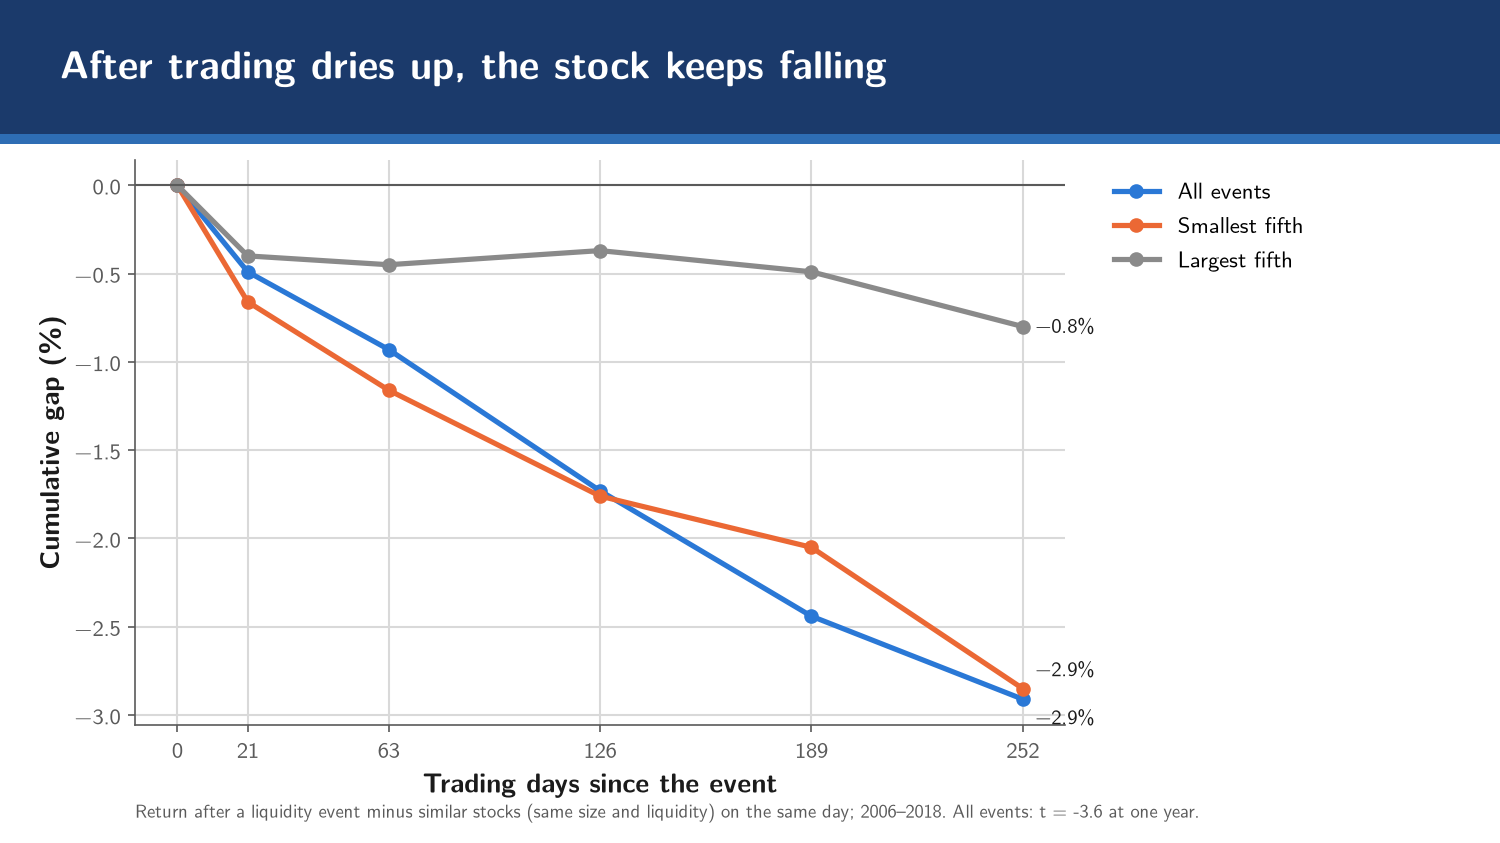

In [8]:
def fig_matched_drift(paper=False):
    m = j(RES / "event_vs_level.json")["matched"]
    ks = [0, 21, 63, 126, 189, 252]
    fig, ax = figure("After trading dries up, the stock keeps falling", paper=paper)
    for key, label, color, dy in (("all", "All events", BLUE, -9), ("size_quintile_1", "Smallest fifth", ORANGE, 9),
                                  ("size_quintile_5", "Largest fifth", GREY, 0)):
        y = [0.0] + [m[key][str(k)]["vs_matched_pct"] for k in ks[1:]]
        ax.plot(ks, y, color=color, linewidth=2.5, marker="o", markersize=6, label=label)
        ax.annotate(f"{y[-1]:+.1f}%".replace("-", "\u2212"), (ks[-1], y[-1]), xytext=(6, dy), textcoords="offset points", va="center",
                    fontsize=10 if not paper else 8, color=style.INK)
    zero_line(ax)
    ax.set_xticks(ks)
    finish(fig, ax, "matched_drift", paper,
           "Return after a liquidity event minus similar stocks (same size and liquidity) on the same day; 2006–2018. All events: t = -3.6 at one year.",
           "Trading days since the event", "Cumulative gap (%)")


fig_matched_drift()
display(Image(filename=str(SLIDES / "figures/matched_drift.png"), width=800))

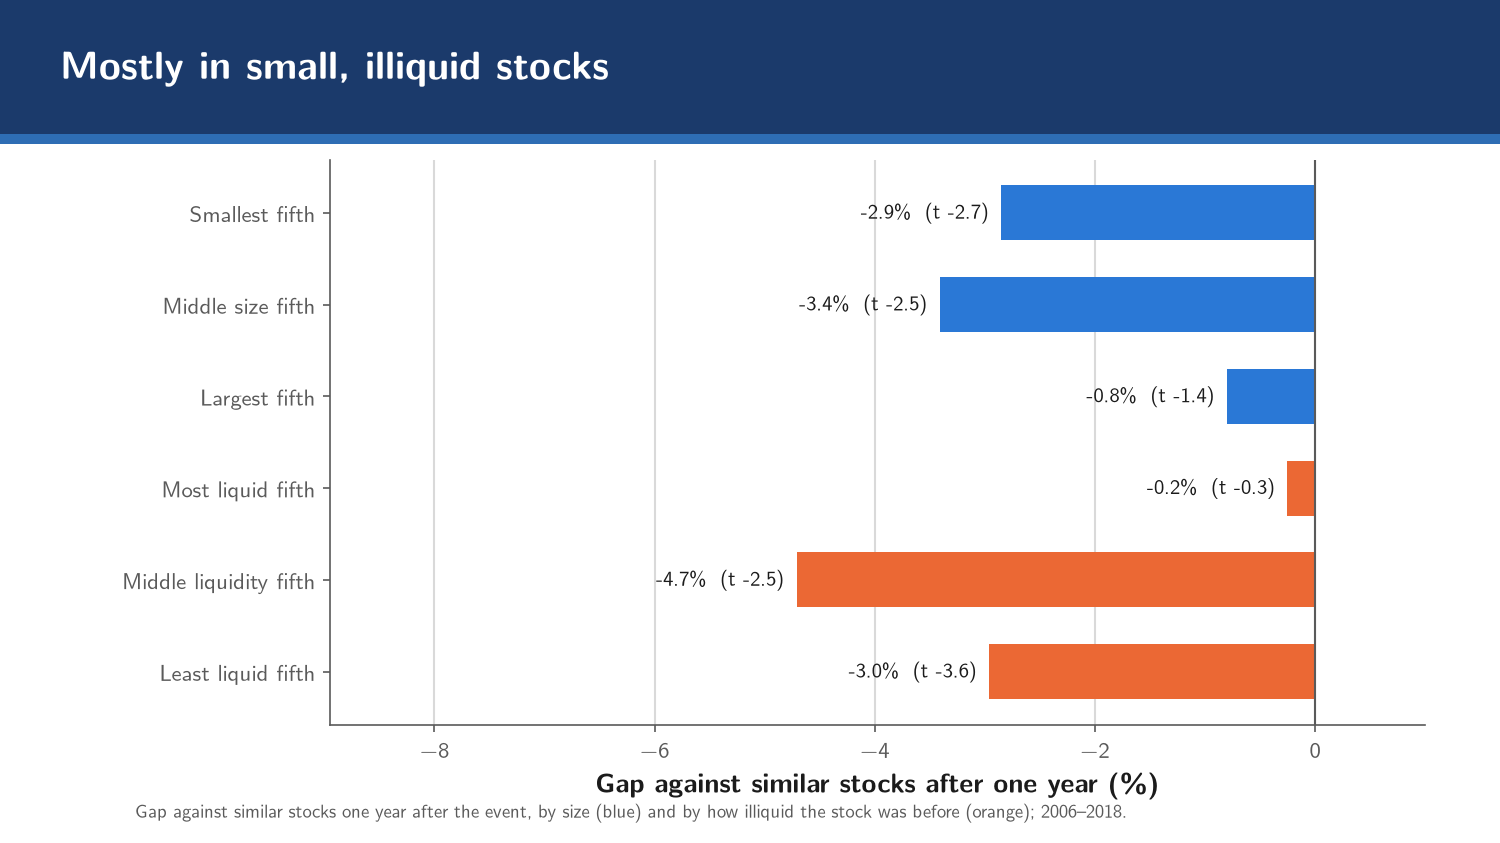

In [9]:
def fig_where(paper=False):
    m = j(RES / "event_vs_level.json")["matched"]
    rows = [("Smallest fifth", "size_quintile_1"), ("Middle size fifth", "size_quintile_3"), ("Largest fifth", "size_quintile_5"),
            ("Most liquid fifth", "illiquidity_quintile_1"), ("Middle liquidity fifth", "illiquidity_quintile_3"),
            ("Least liquid fifth", "illiquidity_quintile_5")]
    fig, ax = figure("Mostly in small, illiquid stocks", wide=True, paper=paper)
    y = np.arange(len(rows))[::-1]
    vals = [m[k]["252"]["vs_matched_pct"] for _, k in rows]
    ts = [m[k]["252"]["t"] for _, k in rows]
    ax.barh(y, vals, color=[BLUE] * 3 + [ORANGE] * 3, height=0.6)
    for yi, v, t in zip(y, vals, ts):
        ax.annotate(f"{v:+.1f}%  (t {t:.1f})", (min(v, 0), yi), xytext=(-6, 0), textcoords="offset points", ha="right", va="center",
                    fontsize=10 if not paper else 8, color=style.INK)
    ax.set_yticks(y, [r for r, _ in rows])
    ax.axvline(0, color=style.MUTED_INK, linewidth=1)
    ax.set_xlim(min(vals) * 1.9, 1)
    ax.grid(False, axis="y")
    if not paper:
        x0, y0, w0, h0 = style.WIDE_RECT
        ax.set_position((0.22, y0, w0 + x0 - 0.22, h0))
    finish(fig, ax, "where", paper, "Gap against similar stocks one year after the event, by size (blue) and by how illiquid the stock was before (orange); 2006–2018.",
           "Gap against similar stocks after one year (%)", "", legend=False)


fig_where()
display(Image(filename=str(SLIDES / "figures/where.png"), width=800))

**Is it a known effect?** Monthly regressions of next month's abnormal return on "had an event in the last month", with size,
prior illiquidity, momentum, long-term reversal and (second model) short-term reversal as controls.

In [10]:
data = panel().sort("barrid", "date").with_columns(c=pl.col("s").fill_null(0.0).log1p().cum_sum().over("barrid")).with_columns(
    strev=pl.col("c") - pl.col("c").shift(21).over("barrid"),
    pre5=pl.col("c") - pl.col("c").shift(5).over("barrid"),
)


days = sorted(data["date"].unique().to_list())


di = pl.DataFrame({"date": days, "t": list(range(len(days)))})


ev = events(data.select("date", "barrid", COLUMN, "market_cap"), COLUMN, FLAG_SHARE)


e = (ev.filter("event").join(data.select("date", "barrid", "pre5"), on=["date", "barrid"]).join(di, on="date")
     .select("barrid", pl.col("date").alias("edate"), pl.col("t").alias("et"), (pl.col("pre5") > 0).alias("rose")).sort("edate"))


month_ends = pl.DataFrame({"date": days}).group_by(pl.col("date").dt.truncate("1mo").alias("month")).agg(pl.col("date").max())["date"]


m = (data.filter(pl.col("date").is_in(month_ends.implode()), pl.col("date") >= dt.date(2008, 1, 1)).join(di, on="date").sort("date")
     .join_asof(e, left_on="date", right_on="edate", by="barrid", strategy="backward")
     .with_columns(age=pl.col("t") - pl.col("et"))
     .with_columns(
         live=pl.col("age").is_between(1, 21).fill_null(False).cast(pl.Float64),
         live63=pl.col("age").is_between(1, 63).fill_null(False).cast(pl.Float64),
     ).with_columns(
         live_rose=pl.col("live") * pl.col("rose").fill_null(False).cast(pl.Float64),
         live_fell=pl.col("live") * (~pl.col("rose").fill_null(True)).cast(pl.Float64),
     )
     .drop_nulls(["target21", "market_cap", "level", "mom", "ltr", "strev"]))


m = m.with_columns([((pl.col(c).rank() / pl.len()).over("date") - 0.5).alias(f"r_{c}") for c in ["market_cap", "level", "mom", "ltr", "strev"]])


BASE = ["r_market_cap", "r_level", "r_mom", "r_ltr"]


def fm(cols):
    coefs = []
    for (_,), g in m.sort("date").group_by(["date"], maintain_order=True):
        x = np.column_stack([np.ones(g.height)] + [g[c].to_numpy() for c in cols])
        coefs.append(np.linalg.lstsq(x, g["target21"].to_numpy(), rcond=None)[0][1:])
    coefs = np.array(coefs)
    return {c: {"coef_pct_month": round(float(coefs[:, i].mean() * 100), 3), "t": round(nw_t(coefs[:, i]), 2)}
            for i, c in enumerate(cols) if not c.startswith("r_") or c == "r_strev"}


out = {
    "months": m["date"].n_unique(), "live_share": float(m["live"].mean()),
    "share_of_live_that_rose": float(m["live_rose"].sum() / m["live"].sum()),
    "corr_live_strev_rank": float(m.select(pl.corr("live", "r_strev")).item()),
    "note": "coefficients in %/month of next-21-day specific return; controls: ranks of size, pre-shock illiquidity, momentum, long-term reversal",
    "fama_macbeth": {
        "live + controls": fm(["live", *BASE]),
        "live + controls + short-term reversal": fm(["live", *BASE, "r_strev"]),
        "live 1-63 + controls + short-term reversal": fm(["live63", *BASE, "r_strev"]),
        "live split by pre-event move + controls": fm(["live_rose", "live_fell", *BASE]),
        "live split by pre-event move + controls + short-term reversal": fm(["live_rose", "live_fell", *BASE, "r_strev"]),
    },
}


(RESULTS / "reversal_check.json").write_text(json.dumps(out, indent=1))


print(json.dumps(out, indent=1), flush=True)

{
 "months": 130,
 "live_share": 0.05653330753229162,
 "share_of_live_that_rose": 0.5020822636773347,
 "corr_live_strev_rank": 0.0005452718883869718,
 "note": "coefficients in %/month of next-21-day specific return; controls: ranks of size, pre-shock illiquidity, momentum, long-term reversal",
 "fama_macbeth": {
  "live + controls": {
   "live": {
    "coef_pct_month": -0.183,
    "t": -2.55
   }
  },
  "live + controls + short-term reversal": {
   "live": {
    "coef_pct_month": -0.167,
    "t": -2.36
   },
   "r_strev": {
    "coef_pct_month": -0.456,
    "t": -2.85
   }
  },
  "live 1-63 + controls + short-term reversal": {
   "live63": {
    "coef_pct_month": -0.193,
    "t": -3.2
   },
   "r_strev": {
    "coef_pct_month": -0.454,
    "t": -2.84
   }
  },
  "live split by pre-event move + controls": {
   "live_rose": {
    "coef_pct_month": -0.281,
    "t": -2.38
   },
   "live_fell": {
    "coef_pct_month": -0.079,
    "t": -0.75
   }
  },
  "live split by pre-event move + contro

In [11]:
fm = json.loads((RESULTS / "reversal_check.json").read_text())["fama_macbeth"]
rows = [("event + controls", fm["live + controls"]["live"]),
        ("event + controls + last month's return", fm["live + controls + short-term reversal"]["live"])]
display(pl.DataFrame({"model": [r[0] for r in rows], "flagged stocks earn less by, %/month": [-r[1]["coef_pct_month"] for r in rows],
                      "t": [-r[1]["t"] for r in rows]}))

model,"flagged stocks earn less by, %/month",t
"""event + controls""",0.18,2.55
"""event + controls + last month'…",0.17,2.36


**Prediction 4: the fall in trading.** The robustness run split the shock into its volume part and its price-move part
(results saved by `scripts/liquidity_checks.py`):

In [12]:
checks = json.loads((RESULTS / "liquidity_checks_dev.json").read_text())["components"]
display(pl.DataFrame([{"part of the shock": k.split(",")[0], "IC": v["ic"], "worst tenth vs average, %/month": v["gap_pct_month"], "t": v["gap_t"]}
                      for k, v in checks.items() if isinstance(v, dict)]))

part of the shock,IC,"worst tenth vs average, %/month",t
"""price-impact part (bigger move…",0.01,-0.24,-3.78
"""volume part (more trading = go…",0.01,-0.58,-6.49


**Prediction 5: already-illiquid stocks earn slightly more.** The event-study run also regressed next month's return on the ranks of illiquidity and size together:

In [13]:
fm = json.loads((RESULTS / "event_vs_level.json").read_text())["fama_macbeth"]["illiquidity + size only"]
display(pl.DataFrame({"rank of": ["illiquidity", "size"], "most minus least, %/month": [fm["r_level"]["coef_pct"], fm["r_market_cap"]["coef_pct"]],
                      "t": [fm["r_level"]["t"], fm["r_market_cap"]["t"]]}))

rank of,"most minus least, %/month",t
"""illiquidity""",0.77,2.78
"""size""",1.65,5.09


Holding size fixed, the most illiquid stocks earn about 0.8% a month more than the most liquid: the patient holders' reward. All five predictions hold. The effect lives in small stocks, which hold little benchmark weight, and that is the practical catch for a long-only fund.

## 5. From signal to alpha

The Grinold–Kahn form says expected abnormal return = forecasting skill × the stock's volatility × the signal. Our signal is a
flag with an age, so `matched_drift` measures, for each age band (1–21 days, 22–63 days, ...), the average gap between
flagged and similar stocks **per unit of each stock's volatility**, and a stock's alpha is its volatility times that rate.
Each January `fit_year` re-estimates the rates from earlier years only, keeps a band only while its past drift is still
negative, never allows a positive rate, and estimates large stocks separately. `EventAlphas` turns the rates into each day's
alpha for the optimizer.

In [14]:
def cumulative(k: np.ndarray, rates: np.ndarray) -> np.ndarray:
    """S(k) = sum of alpha(1..k) for piecewise-constant daily rates per bucket.
    k: (n,), rates: (n, len(BUCKETS)); rates are 0 for buckets past the window."""
    k = np.asarray(k, dtype=float)
    out = np.zeros(len(k))
    for b, (lo, hi) in enumerate(BUCKETS):
        days = np.clip(np.minimum(k, hi) - lo + 1, 0, hi - lo + 1)
        out += rates[:, b] * days
    return out


def alpha_sum(age: np.ndarray, rates: np.ndarray, n: int, length) -> np.ndarray:
    """Sum of alpha over ages age .. age + length - 1; length=None means through N (remaining drift).
    Stocks without a live event (age <= 0, NaN or > N) get 0."""
    age = np.nan_to_num(np.asarray(age, dtype=float), nan=0.0)
    live = (age >= 1) & (age <= n)
    end = np.minimum(np.full_like(age, n) if length is None else age + length - 1, n)
    return np.where(live, cumulative(end, rates) - cumulative(age - 1, rates), 0.0)


def fit_year(drift: pl.DataFrame, before: dt.date) -> dict:
    """Window and alpha from events whose bucket ended before `before`."""
    known = drift.filter(pl.col("end") < before)
    stats, n_window = [], 0
    rates = {g: [0.0] * len(BUCKETS) for g in GROUPS}
    for b, (lo, hi) in enumerate(BUCKETS):
        x = known.filter(pl.col("bucket") == b)
        pooled = x.group_by("date").agg(((pl.col("drift") * pl.col("n")).sum() / pl.col("n").sum()).alias("d")).sort("date")
        t = nw_t(pooled["d"].to_numpy(), lags=min(hi, 252)) if pooled.height > 20 else float("nan")
        by_group = {}
        for g in (0, 1):
            xg = x.filter(pl.col("group") == g)
            v = float((xg["drift"] * xg["n"]).sum() / xg["n"].sum()) if xg.height else 0.0
            by_group[GROUPS[g]] = v if np.isfinite(v) else 0.0
        stats.append({"bucket": [lo, hi], "event_dates": pooled.height, "pooled_bp_per_day": float(pooled["d"].mean() * 1e4) if pooled.height else None,
                      "t": t, **{f"{k}_bp_per_day": v * 1e4 for k, v in by_group.items()}})
        if n_window == lo - 1 and np.isfinite(t) and t <= STOP_T:
            n_window = hi
            for k, v in by_group.items():
                rates[k][b] = min(v, 0.0)  # raw estimates stay in stats
    return {"half_life": 0, "flag_share": FLAG_SHARE, "window": n_window, "rates": rates, "buckets": stats}


def sign_check(data: pl.DataFrame, ev: pl.DataFrame, di: dict, chosen: dict) -> dict:
    """Monthly Fama-MacBeth at month-ends 2008-END: next-month specific return on live (that year's
    window), size, illiquidity, momentum and long-term reversal, all as cross-sectional ranks."""
    a = ages(data.select("date", "barrid", "market_cap", "level", "mom", "ltr", "target21"), ev, di)
    month_ends = pl.DataFrame({"date": list(di)}).group_by(pl.col("date").dt.truncate("1mo").alias("month")).agg(pl.col("date").max())["date"]
    windows = pl.DataFrame({"year": [int(y) for y in chosen], "n": [p["window"] for p in chosen.values()]})
    m = (a.filter(pl.col("date").is_in(month_ends.implode()), pl.col("date") >= dt.date(2008, 1, 1))
         .with_columns(year=pl.col("date").dt.year()).join(windows, on="year", how="left").with_columns(pl.col("n").fill_null(0))
         .with_columns(live=(pl.col("age").is_between(1, pl.col("n"))).fill_null(False).cast(pl.Float64))
         .drop_nulls(["target21", "market_cap", "level", "mom", "ltr"]))
    m = m.with_columns([((pl.col(c).rank() / pl.len()).over("date") - 0.5).alias(f"r_{c}") for c in ["market_cap", "level", "mom", "ltr"]])
    cols = ["live", "r_market_cap", "r_level", "r_mom", "r_ltr"]
    coefs = []
    for (_,), g in m.sort("date").group_by(["date"], maintain_order=True):
        if g["live"].sum() == 0:
            continue
        x = np.column_stack([np.ones(g.height)] + [g[c].to_numpy() for c in cols])
        coefs.append(np.linalg.lstsq(x, g["target21"].to_numpy(), rcond=None)[0][1])
    coefs = np.array(coefs)
    return {"months": len(coefs), "live_share": float(m["live"].mean()),
            "live_coef_pct_month": float(coefs.mean() * 100), "t": nw_t(coefs)}


def params() -> None:
    """Walk-forward stage 1; writes EVENT_PARAMS, event_drift.parquet and event_sensitivity.json."""
    data = panel()
    print(f"panel: {data.height} scored stock-days", flush=True)
    drift, ev, di = matched_drift(data, FLAG_SHARE)
    drift.write_parquet(OPT / "event_drift.parquet")
    chosen = {}
    for year in range(CFG["optimizer"]["first_year"], END.year + 1):
        chosen[str(year)] = fit_year(drift, dt.date(year, 1, 1))
        p = chosen[str(year)]
        print(year, "window", p["window"], {g: [round(r * 1e4, 2) for r in v] for g, v in p["rates"].items()},
              "t by bucket", [round(s["t"], 1) if s["t"] == s["t"] else None for s in p["buckets"]], flush=True)
    EVENT_PARAMS.write_text(json.dumps(chosen, indent=1, default=str))
    # The fixed flag share's neighbours, for the paper; not used by the backtests.
    sens = {}
    for share in E["sensitivity_shares"]:
        d, _, _ = matched_drift(data, share)
        sens[str(share)] = fit_year(d, dt.date(END.year + 1, 1, 1))
    (OPT / "event_sensitivity.json").write_text(json.dumps(sens, indent=1, default=str))
    check = sign_check(data, ev, di, chosen)
    (OPT / "event_sign_check.json").write_text(json.dumps(check, indent=1))
    print("sign check:", json.dumps(check), flush=True)
    if any(p["window"] == 0 for p in chosen.values()):
        print("note: some years have no significant first bucket and carry no alpha", flush=True)
    if not (check["live_coef_pct_month"] < 0) and not HOLDOUT:  # holdout: frozen design, report only
        raise SystemExit(f"sign check failed: live coefficient {check['live_coef_pct_month']:+.3f}%/month (t {check['t']:.2f}) "
                         "does not agree with the negative alpha; stopping before any backtest")


class EventAlphas:
    """Alpha for each backtest day from the event clock, with year Y's settings from EVENT_PARAMS."""

    def __init__(self, lo: dt.date, hi: dt.date):
        guard(hi)
        self.params = json.loads(EVENT_PARAMS.read_text())
        start = lo - dt.timedelta(days=int(max(EDGES) * 1.5) + 30)  # older events are still live
        sm = pl.read_parquet(SMOOTHED, columns=["date", "barrid", COLUMN]).filter(pl.col("date").is_between(start, hi))
        caps = (features(["date", "barrid", "market_cap", "eligible", "amihud63", "ivol63"], years=range(start.year, hi.year + 1))
                .filter(pl.col("date").is_between(start, hi)).collect().sort("barrid", "date")
                .with_columns(level=pl.col("amihud63").shift(63).over("barrid"))
                .filter(pl.col("eligible")).select("date", "barrid", "market_cap", "level", pl.col("ivol63").alias("vol")))
        data = sm.join(caps, on=["date", "barrid"], how="inner")
        # matched-drift cells (as in panel()): size fifth x pre-shock illiquidity fifth; 25 = no cell
        cells = data.with_columns(
            sq=((pl.col("market_cap").rank() / pl.len()).over("date") * 5).ceil().clip(1, 5).cast(pl.Int32),
            lq=((pl.col("level").rank() / pl.len()).over("date") * 5).ceil().clip(1, 5).cast(pl.Int32),
        ).select("date", "barrid", ((pl.col("sq") - 1) * 5 + pl.col("lq") - 1).fill_null(25).alias("cell"))
        self.cells_by_date = {d: g for (d,), g in cells.group_by(["date"])}
        days = sorted(data["date"].unique().to_list())
        self.day_index = {d: i for i, d in enumerate(days)}
        ev = events(data.select("date", "barrid", COLUMN, "market_cap", "vol"), COLUMN, FLAG_SHARE)
        a = ages(data.select("date", "barrid"), ev, self.day_index)
        self.by_date = {d: g for (d,), g in a.group_by(["date"])}

    def cells(self, signal_date: dt.date, ids: np.ndarray) -> np.ndarray:
        """Matched-drift cell (0-24) of each asset on signal_date; 25 = unscored or no illiquidity history."""
        day = self.cells_by_date.get(signal_date)
        if day is None:
            return np.full(len(ids), 25)
        return pl.DataFrame({"barrid": ids}).join(day, on="barrid", how="left", maintain_order="left")["cell"].fill_null(25).to_numpy()

    def __call__(self, signal_date: dt.date, year: int, ids: np.ndarray, frequency: str, costs: bool):
        """Returns (alpha for the optimizer, alpha for the transfer coefficient, flagged mask) for the
        weights dated the trading day after signal_date."""
        p = self.params[str(year)]
        n = p["window"]
        day = self.by_date.get(signal_date)
        zero = np.zeros(len(ids))
        if day is None or n == 0:
            return zero, zero, zero.astype(bool)
        j = pl.DataFrame({"barrid": ids}).join(day.select("barrid", "age", "event_group", "event_vol"), on="barrid", how="left", maintain_order="left")
        age = j["age"].cast(pl.Float64).to_numpy() + 1  # one day later than signal_date
        grp = j["event_group"].fill_null(0).to_numpy()
        rates = np.where((grp == 1)[:, None], np.array(p["rates"]["large"])[None, :], np.array(p["rates"]["rest"])[None, :])
        vol = j["event_vol"].fill_null(0.0).fill_nan(0.0).to_numpy()  # rates are per unit of event-day vol
        nxt = alpha_sum(age, rates, n, 1 if frequency == "daily" else CFG["optimizer"]["days_per_month"]) * vol
        opt = (alpha_sum(age, rates, n, None) * vol) if costs else nxt
        a = np.nan_to_num(age, nan=0)
        return opt, nxt, (a >= 1) & (a <= n)

For each year: the holding window, the rates by age band (per unit of volatility, ×10,000) for smaller and large stocks, and each band's t-statistic.

In [15]:
params()      # 2011-2018

panel: 8609368 scored stock-days
2011 window 126 {'rest': [-5.91, -1.65, -0.95, 0.0, 0.0, 0.0], 'large': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]} t by bucket [-2.0, -0.3, -0.1, 1.7, 1.7, -0.8]
2012 window 63 {'rest': [-5.16, -2.23, 0.0, 0.0, 0.0, 0.0], 'large': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]} t by bucket [-1.9, -1.0, 0.0, 1.2, 0.4, -1.3]
2013 window 126 {'rest': [-5.11, -1.7, -0.5, 0.0, 0.0, 0.0], 'large': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]} t by bucket [-2.3, -1.2, -0.1, 0.9, -0.0, -1.9]
2014 window 63 {'rest': [-4.39, -1.12, 0.0, 0.0, 0.0, 0.0], 'large': [-0.08, -0.0, 0.0, 0.0, 0.0, 0.0]} t by bucket [-2.2, -0.7, 0.0, 0.7, -0.7, -1.9]
2015 window 63 {'rest': [-4.81, -0.92, 0.0, 0.0, 0.0, 0.0], 'large': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]} t by bucket [-2.7, -0.6, 0.0, 0.3, -1.0, -0.9]
2016 window 63 {'rest': [-4.3, -1.13, 0.0, 0.0, 0.0, 0.0], 'large': [-0.79, -0.29, 0.0, 0.0, 0.0, 0.0]} t by bucket [-2.7, -1.0, 0.3, 0.5, -1.1, -1.6]
2017 window 63 {'rest': [-4.16, -0.53, 0.0, 0.0, 0.0, 0.0], 'large': 

In [16]:
# design frozen; same code with LAB_HOLDOUT=1, which extends the end date to 2024 and writes to output/optimizer_holdout
params()

panel: 12594479 scored stock-days
2011 window 126 {'rest': [-5.91, -1.65, -0.95, 0.0, 0.0, 0.0], 'large': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]} t by bucket [-2.0, -0.3, -0.1, 1.7, 1.7, -0.8]
2012 window 63 {'rest': [-5.16, -2.23, 0.0, 0.0, 0.0, 0.0], 'large': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]} t by bucket [-1.9, -1.0, 0.0, 1.2, 0.4, -1.3]
2013 window 126 {'rest': [-5.11, -1.7, -0.5, 0.0, 0.0, 0.0], 'large': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]} t by bucket [-2.3, -1.2, -0.1, 0.9, -0.0, -1.9]
2014 window 63 {'rest': [-4.39, -1.12, 0.0, 0.0, 0.0, 0.0], 'large': [-0.08, -0.0, 0.0, 0.0, 0.0, 0.0]} t by bucket [-2.2, -0.7, 0.0, 0.7, -0.7, -1.9]
2015 window 63 {'rest': [-4.81, -0.92, 0.0, 0.0, 0.0, 0.0], 'large': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]} t by bucket [-2.7, -0.6, 0.0, 0.3, -1.0, -0.9]
2016 window 63 {'rest': [-4.3, -1.13, 0.0, 0.0, 0.0, 0.0], 'large': [-0.79, -0.29, 0.0, 0.0, 0.0, 0.0]} t by bucket [-2.7, -1.0, 0.3, 0.5, -1.1, -1.6]
2017 window 63 {'rest': [-4.16, -0.53, 0.0, 0.0, 0.0, 0.0], 'large':

**Why volatility belongs in the alpha.** An earlier version left the volatility term out and gave every flagged stock the
same alpha. The optimizer then favored calm stocks, where the same expected drift looks like a better deal. A diagnostic
compared expected and realized return by fifth of predicted volatility:

In [17]:
assert not HOLDOUT, "development years only"


lo, hi = O["start"], RUN_END


alphas = EventAlphas(lo, hi)


prev = previous_day(trading_days(lo - dt.timedelta(days=10), hi))


spec = features(["date", "barrid", "s"], years=range(lo.year, hi.year + 1)).filter(pl.col("date").is_between(lo, hi)).collect()


spec = {d: g for (d,), g in spec.group_by(["date"])}


out = {}


for name in ("U-D", "C-D"):
    w, _ = load_run(STEMS[name])
    frames = []
    for (date_,), g in w.group_by(["date"]):
        if date_ not in spec:
            continue
        c = load_cache(date_)
        ids = c["ids"]
        base = pl.DataFrame({"barrid": ids})
        h = base.join(g.select("barrid", "active_weight"), on="barrid", how="left", maintain_order="left")["active_weight"].fill_null(0.0).to_numpy()
        _, a, _ = alphas(prev[date_], date_.year, ids, "daily", False)
        s = base.join(spec[date_].select("barrid", "s"), on="barrid", how="left", maintain_order="left")["s"].to_numpy()
        vol = np.sqrt(c["D"])  # annual predicted specific risk
        q = np.ceil(pl.Series(vol).rank().to_numpy() / len(vol) * 5).clip(1, 5).astype(int)
        frames.append(pl.DataFrame({"date": [date_] * len(ids), "h": h, "a": a, "s": s, "vol": vol, "q": q, "has_alpha": a != 0}))
    d = pl.concat(frames).filter(pl.col("s").is_not_null())
    n_days = d["date"].n_unique()
    by = (d.group_by("q", "has_alpha").agg(
        expected=(pl.col("a") * pl.col("h")).sum() / n_days * 252 * 100,
        realized=(pl.col("h") * pl.col("s")).sum() / n_days * 252 * 100,
        gross=pl.col("h").abs().sum() / n_days,
        net=pl.col("h").sum() / n_days,
        bias=(pl.col("s") ** 2 / (pl.col("vol") ** 2 / 252)).mean(),
        mean_predicted_vol=pl.col("vol").mean() * 100,
    ).sort("has_alpha", "q", descending=[True, False]))
    out[name] = {"days": n_days,
                 "expected_total": float((d["a"] * d["h"]).sum() / n_days * 252 * 100),
                 "realized_total": float((d["h"] * d["s"]).sum() / n_days * 252 * 100),
                 "by_risk_fifth": by.to_dicts()}
    with pl.Config(tbl_rows=20, tbl_cols=12, float_precision=3):
        print(name, {k: v for k, v in out[name].items() if k != "by_risk_fifth"}, flush=True)
        print(by, flush=True)


(ANALYSIS / "no_limits_diagnostic.json").write_text(json.dumps(out, indent=1, default=str))

U-D {'days': 2012, 'expected_total': 15.087825574417646, 'realized_total': 3.316068098009627}
shape: (10, 8)
┌─────┬───────────┬──────────┬──────────┬───────┬────────┬───────┬────────────────────┐
│ q   ┆ has_alpha ┆ expected ┆ realized ┆ gross ┆ net    ┆ bias  ┆ mean_predicted_vol │
│ --- ┆ ---       ┆ ---      ┆ ---      ┆ ---   ┆ ---    ┆ ---   ┆ ---                │
│ i64 ┆ bool      ┆ f64      ┆ f64      ┆ f64   ┆ f64    ┆ f64   ┆ f64                │
╞═════╪═══════════╪══════════╪══════════╪═══════╪════════╪═══════╪════════════════════╡
│ 1   ┆ true      ┆ 4.298    ┆ 1.527    ┆ 1.222 ┆ -0.977 ┆ 1.064 ┆ 12.776             │
│ 2   ┆ true      ┆ 3.809    ┆ 2.769    ┆ 0.986 ┆ -0.729 ┆ 1.106 ┆ 18.615             │
│ 3   ┆ true      ┆ 3.444    ┆ 2.535    ┆ 0.825 ┆ -0.608 ┆ 1.143 ┆ 24.581             │
│ 4   ┆ true      ┆ 2.495    ┆ 2.975    ┆ 0.574 ┆ -0.405 ┆ 1.211 ┆ 32.872             │
│ 5   ┆ true      ┆ 1.042    ┆ 1.571    ┆ 0.224 ┆ -0.162 ┆ 1.277 ┆ 49.532             │
│ 1   ┆ fal

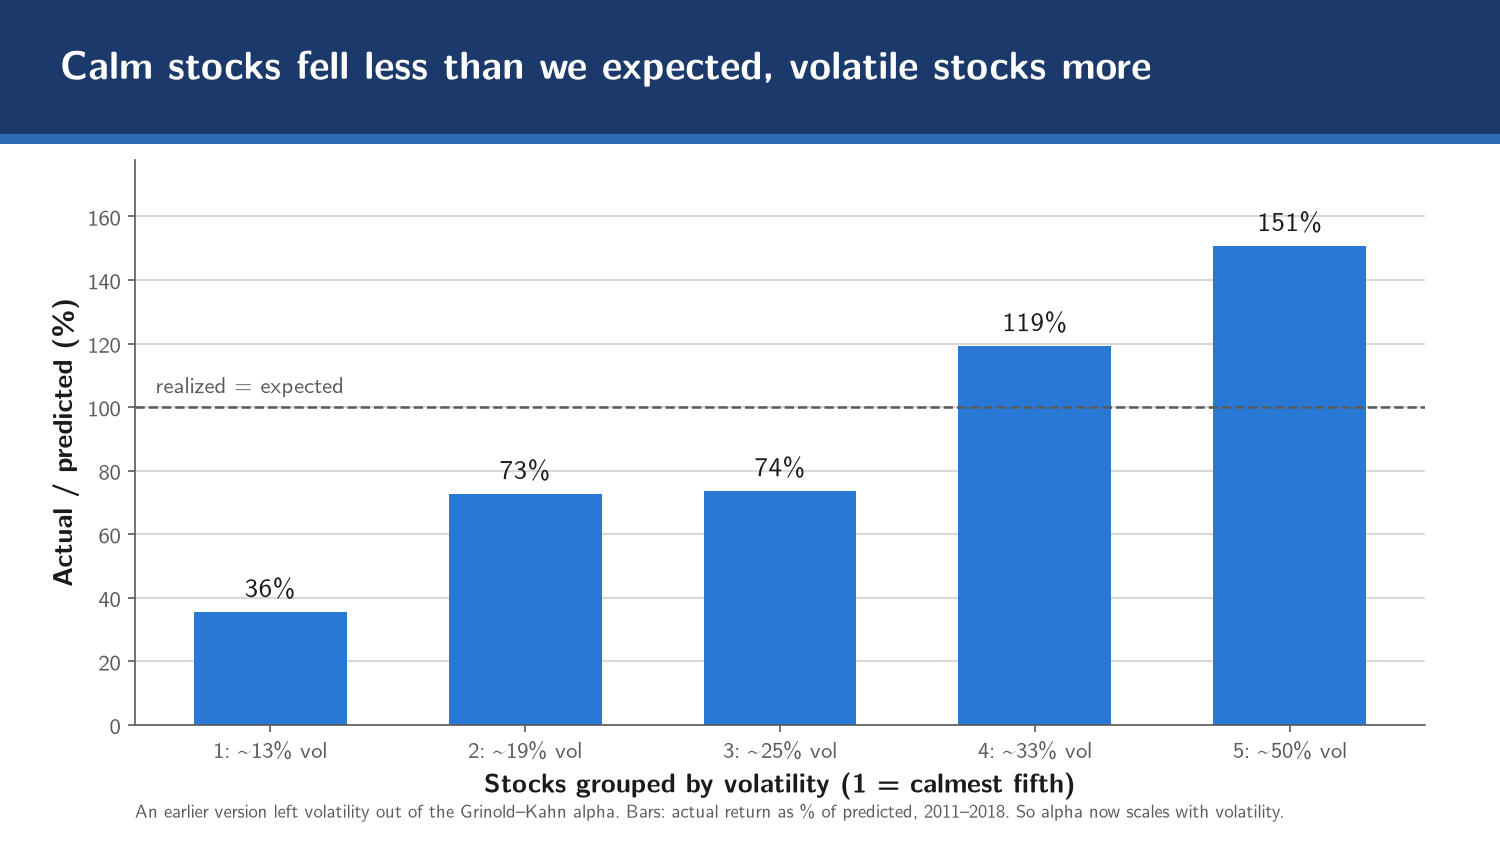

In [18]:
def fig_vol_check(paper=False):
    """Slide: in the version with the same alpha for every flagged stock, realized vs expected return by volatility fifth."""
    d = j(OPT / "v3_event_clock/analysis/no_limits_diagnostic.json")["U-D"]["by_risk_fifth"]
    rows = sorted([r for r in d if r["has_alpha"]], key=lambda r: r["q"])
    ratio = [r["realized"] / r["expected"] * 100 for r in rows]
    vol = [r["mean_predicted_vol"] for r in rows]
    fig, ax = figure("Calm stocks fell less than we expected, volatile stocks more", wide=True, paper=paper)
    labels = [f"{i + 1}: ~{v:.0f}% vol" for i, v in enumerate(vol)]
    ax.bar(range(5), ratio, color=BLUE, width=0.6)
    ax.axhline(100, color=style.MUTED_INK, linewidth=1.2, linestyle="--")
    ax.text(-0.45, 103, "realized = expected", ha="left", va="bottom", fontsize=11, color=style.MUTED_INK)
    for i, v in enumerate(ratio):
        ax.text(i, v + 3, f"{v:.0f}%", ha="center", va="bottom", fontsize=9 if paper else 13, color=style.INK)
    ax.set_xticks(range(5), labels)
    ax.set_ylim(0, max(ratio) * 1.18)
    ax.grid(False, axis="x")
    finish(fig, ax, "vol_check", paper,
           "An earlier version left volatility out of the Grinold–Kahn alpha. Bars: actual return as % of predicted, 2011–2018. So alpha now scales with volatility.",
           "Stocks grouped by volatility (1 = calmest fifth)", "Actual / predicted (%)", legend=False)


fig_vol_check()
display(Image(filename=str(SLIDES / "figures/vol_check.png"), width=800))

Calm flagged stocks delivered about a third of the prediction and the most volatile half again as much. The drift scales with volatility, so the final alpha does too.

## 6. Building the portfolio

Active weights $h = w - b$ maximize expected active return minus a risk penalty, $h^\top\alpha - \tfrac{\gamma}{2}h^\top V h$
with Barra's covariance matrix $V$, subject to zero net investment ($\sum h = 0$), zero beta to the benchmark, a 5% tracking
error limit, and zero net active weight within each similar-stock group. $\gamma$ is set each day so the portfolio without
the long-only rule sits at 5% tracking error. **Two portfolios:** *no limits*, and *no shorting* (a stock's weight can be cut
to zero but not below, $b + h \ge 0$), each rebalanced daily and monthly. Weights for day $t$ use only day $t-1$'s close.

The **transfer coefficient** (TC) measures how much of the forecast survives the long-only rule: the fundamental law
$IR = IC\sqrt{BR}$ becomes $IR = TC \times IC\sqrt{BR}$ (Clarke, de Silva and Thorley 2002). **No trading costs** are
charged, since the signal would be one input to the fund's alpha where trades net out; what each portfolio would pay in
bid–ask spreads alone is reported.

In [19]:
O = CFG["optimizer"]
RUN_END = END
RUNS_DIR = OPT / "runs"
ANALYSIS = OPT / "analysis"


CACHE = OUTPUT / "optimizer" / "cache"


START = CFG["window"]["holdout_start"] if HOLDOUT else O["start"]


FIRST_YEAR = START.year if HOLDOUT else O["first_year"]


RUNS = {  # name: (frequency, long-only, charges costs)
    "U-D": ("daily", False, False), "C-D": ("daily", True, False), "CC-D": ("daily", True, True),
    "CC-M": ("monthly", True, True), "U-M": ("monthly", False, False),
    "C-M": ("monthly", True, False),  # run separately by extra_backtest()
}


def trading_days(lo: dt.date, hi: dt.date) -> list[dt.date]:
    guard(hi)
    years = range(lo.year, hi.year + 1)
    days = features(["date"], years=years).filter(pl.col("date").is_between(lo, hi)).unique().collect()["date"].sort()
    return days.to_list()


def previous_day(days: list[dt.date]) -> dict:
    return {d: p for p, d in zip(days[:-1], days[1:])}


def fill_spreads(spreads: pl.DataFrame) -> pl.DataFrame:
    """Blank spreads take the stock's last known spread, else that day's median (no look-ahead)."""
    return (
        spreads.sort("barrid", "date")
        .with_columns(pl.col("half_spread").forward_fill().over("barrid"))
        .with_columns(pl.col("half_spread").fill_null(pl.col("half_spread").median().over("date")))
    )


def risk_components(date_: dt.date, ids: list[str]):
    try:
        return ids, construct_factor_model_components(date_, ids)
    except ValueError:
        have = set(sfd.load_exposures_by_date(date_)["barrid"].to_list())
        kept = [b for b in ids if b in have]
        return kept, construct_factor_model_components(date_, kept)


def cache_year(year: int, smoke: bool = False) -> None:
    """One .npz per trading day: ids, B (exposures), F (factor cov), D (specific var), beta, b, c."""
    CACHE.mkdir(parents=True, exist_ok=True)
    lo, hi = max(dt.date(year, 1, 1), O["cache_start"]), min(dt.date(year, 12, 31), END)
    if smoke:
        hi = min(hi, dt.date(2011, 3, 31))
    days = trading_days(lo - dt.timedelta(days=10), hi)
    prev = previous_day(days)
    days = [d for d in days if d >= lo]
    assets = sfd.load_assets(lo, hi, ["date", "barrid", "predicted_beta"], in_universe=True).drop_nulls("predicted_beta")
    bench = sfd.load_benchmark(lo, hi).rename({"weight": "b"})
    spreads = fill_spreads(sfd.load_half_spreads(lo - dt.timedelta(days=60), hi)).rename({"date": "prev"})
    started = time.time()
    for k, date_ in enumerate(days):
        path = CACHE / f"{date_}.npz"
        if path.exists():
            continue
        day = (
            assets.filter(pl.col("date") == date_).join(bench.filter(pl.col("date") == date_).drop("date"), on="barrid", how="left")
            .join(spreads.filter(pl.col("prev") == prev[date_]).drop("prev"), on="barrid", how="left")
            .with_columns(pl.col("half_spread").fill_null(pl.col("half_spread").median()))
            .with_columns(pl.col("b").fill_null(0.0), pl.col("half_spread").fill_null(0.0)).sort("barrid")
        )
        ids, (B, F, D) = risk_components(date_, day["barrid"].to_list())
        day = pl.DataFrame({"barrid": ids}).join(day, on="barrid", how="left", maintain_order="left")
        tmp = path.with_name(path.stem + ".tmp.npz")  # write then rename, so an interrupted job leaves no broken file
        np.savez(tmp, ids=np.array(ids), B=B.astype(np.float32), F=F, D=D, beta=day["predicted_beta"].to_numpy(),
                 b=day["b"].to_numpy(), c=day["half_spread"].to_numpy())
        tmp.rename(path)
        if k % 50 == 0:
            print(f"cache {date_}: {len(ids)} names, {time.time() - started:.0f}s so far", flush=True)
    print(f"cache {year}: {len(days)} days in {time.time() - started:.0f}s", flush=True)


def load_cache(date_: dt.date) -> dict:
    z = np.load(CACHE / f"{date_}.npz")
    return {k: z[k] for k in z.files}


def daily_returns(lo: dt.date, hi: dt.date) -> dict:
    guard(hi)
    r = sfd.load_assets(lo, hi, ["date", "barrid", "return"], in_universe=False).drop_nulls("return").with_columns(
        pl.col("return") / 100)
    return {d: g.select("barrid", "return") for (d,), g in r.group_by(["date"])}


def risk_aversion(alpha, B, F, D) -> float:
    """gamma = sqrt(alpha' V^-1 alpha) / target, so the unconstrained optimum V^-1 alpha / gamma has
    exactly the target risk. V = B F B' + diag(D), inverted with the Woodbury identity."""
    u = alpha / D
    w = B.T @ u
    m = np.linalg.inv(F) + (B.T * (1 / D)) @ B
    q = float(alpha @ u - w @ np.linalg.solve(m, w))
    return math.sqrt(max(q, 0.0)) / O["target_risk"]


def solve(alpha, B, F, D, constraints, before, c, lam, b, beta, gamma, groups=None):
    """max alpha'h - lam * c'|h - before| - (gamma/2) h'Vh, with the risk cap and constraints.
    groups (int per asset): net active weight is zero within each group."""
    h = cp.Variable(len(alpha))
    risk = cp.quad_form(B.T @ h, F) + cp.sum_squares(cp.multiply(np.sqrt(D), h))
    objective = alpha @ h - gamma / 2 * risk - (lam * (c @ cp.abs(h - before)) if lam > 0 else 0)
    cons = [risk <= O["target_risk"] ** 2] + [k(h) for k in _construct_constraints(constraints, betas=beta, benchmark_weights=b)]
    if groups is not None:
        G = (groups[None, :] == np.unique(groups)[:, None]).astype(float)
        cons.append(G @ h == 0)
    problem = cp.Problem(cp.Maximize(objective), cons)
    try:
        problem.solve(solver="CLARABEL", max_threads=1)
    except cp.error.SolverError:
        problem.solve(solver="SCS", max_iters=20000)
    if problem.status not in ("optimal", "optimal_inaccurate") or h.value is None:
        return None
    return h.value


def drift(held: pl.DataFrame, growth: pl.DataFrame) -> pl.DataFrame:
    """Total weights after compounded returns: w (1 + R) / (1 + w'R)."""
    j = held.join(growth, on="barrid", how="left").with_columns(pl.col("R").fill_null(0.0))
    return j.select("barrid", (pl.col("total") * (1 + pl.col("R")) / (1 + (pl.col("total") * pl.col("R")).sum())).alias("drifted"))


def growth(returns: dict, dates: list[dt.date]) -> pl.DataFrame:
    frames = [returns[d] for d in dates if d in returns]
    if not frames:
        return pl.DataFrame(schema={"barrid": pl.String, "R": pl.Float64})
    return pl.concat(frames).group_by("barrid").agg((pl.col("return") + 1).product().sub(1).alias("R"))


def run(name: str, lam, lo: dt.date, hi: dt.date, out: str, start=None) -> None:
    """``lam`` is a number or {year: lambda}. ``start`` = (held total weights, their date, earlier frames,
    earlier log rows) resumes a run already computed up to lo. Writes RUNS_DIR/{out}.parquet and {out}_days.parquet."""
    frequency, long_only, costs = RUNS[name]
    constraints = [ZeroInvestment(), ZeroBeta()] + ([LongOnly()] if long_only else [])
    first = min(lo - dt.timedelta(days=10), start[1]) if start else lo - dt.timedelta(days=10)
    all_days = trading_days(first, hi)
    prev = previous_day(all_days)
    days = [d for d in all_days if d >= lo]
    rebalance = days if frequency == "daily" else [d for k, d in enumerate(days) if k == 0 or d.month != days[k - 1].month]
    returns = daily_returns(first, hi)
    alphas = EventAlphas(lo, hi)
    gamma = None
    caps = features(["date", "barrid", "market_cap"], years=range(lo.year, hi.year + 1)).filter(
        pl.col("date").is_between(lo - dt.timedelta(days=10), hi)).collect()
    caps = {d: g for (d,), g in caps.group_by(["date"])}
    held, held_date, frames, rows = start if start else (None, None, [], [])
    started = time.time()
    for k, date_ in enumerate(rebalance):
        c = load_cache(date_)
        ids, beta = c["ids"], c["beta"]
        # Cached b on day D is end-of-day (it already includes D's return); the weights held during D
        # are the previous day's.
        p = load_cache(prev[date_])
        b = pl.DataFrame({"barrid": ids}).join(pl.DataFrame({"barrid": p["ids"], "b": p["b"]}), on="barrid", how="left",
                                               maintain_order="left")["b"].fill_null(0.0).to_numpy()
        alpha, alpha_tc, flagged = alphas(prev[date_], date_.year, ids, frequency, costs)
        if held is None:
            before, exits = np.zeros(len(ids)), 0.0
        else:
            span = [d for d in all_days if held_date <= d < date_]
            drifted = drift(held, growth(returns, span))
            before = pl.DataFrame({"barrid": ids}).join(drifted, on="barrid", how="left", maintain_order="left")[
                "drifted"].fill_null(0.0).to_numpy() - b
            exits = float(drifted.filter(~pl.col("barrid").is_in(list(ids)))["drifted"].abs().sum())
        lam_d = (lam[str(date_.year)] if isinstance(lam, dict) else lam) if costs else 0.0
        B64 = c["B"].astype(np.float64)
        if np.any(alpha != 0):
            gamma = risk_aversion(alpha, B64, c["F"], c["D"])
        try:
            if gamma is None:  # no live events yet: stay at the benchmark
                h, status = np.zeros(len(ids)), "no_alpha"
            else:
                groups = alphas.cells(prev[date_], ids)
                h, status = solve(alpha, B64, c["F"], c["D"], constraints, before, c["c"], lam_d, b, beta, gamma, groups), "ok"
                if h is None:
                    h, status = before.copy(), "failed"
        except (ValueError, cp.error.SolverError, np.linalg.LinAlgError):
            h, status = before.copy(), "failed"
        x = B64.T @ h
        risk = float(np.sqrt(max(0.0, x @ c["F"] @ x + (c["D"] * h ** 2).sum())))
        trade = np.abs(h - before)
        cap = caps.get(prev[date_])
        small = np.zeros(len(ids), dtype=bool)
        if cap is not None:
            m = pl.DataFrame({"barrid": ids}).join(cap.select("barrid", "market_cap"), on="barrid", how="left", maintain_order="left")["market_cap"]
            cutoff = m.drop_nulls().quantile(1 / 3)
            small = (m.fill_null(0.0) <= cutoff).to_numpy()
        absh = np.abs(h).sum()
        exp = c["B"].astype(np.float64).T @ h
        factor_var = float(exp @ c["F"] @ exp)  # Barra covariances are annual
        specific_var = float((h ** 2 * c["D"]).sum())
        rows.append({
            "date": date_, "status": status, "lambda": lam_d, "names": len(ids), "flagged": int(flagged.sum()),
            "alpha_h": float(alpha_tc @ h), "alpha_opt_h": float(alpha @ h), "gamma": gamma or 0.0, "active_risk": risk, "turnover": float(trade.sum() + exits),
            "cost": float((c["c"] * trade).sum()) if costs else 0.0,
            "underweights": int((h < -1e-6).sum()), "min_total_weight": float((h + b).min()),
            "sum_h": float(h.sum()), "beta_h": float(beta @ h),
            "flagged_share_abs": float(np.abs(h[flagged]).sum() / absh) if absh > 0 else 0.0,
            "small_share_abs": float(np.abs(h[small]).sum() / absh) if absh > 0 else 0.0,
            "factor_risk_share": factor_var / (factor_var + specific_var) if factor_var + specific_var > 0 else float("nan"),
        })
        frames.append(pl.DataFrame({"date": [date_] * len(ids), "barrid": ids, "active_weight": h}))
        held, held_date = pl.DataFrame({"barrid": ids, "total": h + b}), date_
        if k % 100 == 0:
            print(f"{out} {date_}: {status}, risk {risk:.4f}, {time.time() - started:.0f}s", flush=True)
    RUNS_DIR.mkdir(parents=True, exist_ok=True)
    (RUNS_DIR / out).parent.mkdir(parents=True, exist_ok=True)
    pl.concat(frames).write_parquet(RUNS_DIR / f"{out}.parquet")
    log = pl.DataFrame(rows)
    log.write_parquet(RUNS_DIR / f"{out}_days.parquet")
    print(json.dumps({"run": out, "rebalances": log.height, "failed": int((log["status"] == "failed").sum()),
                      "seconds": round(time.time() - started)}), flush=True)


def backtest_tasks() -> list[tuple]:
    """(run, lambda, year or None). No-cost daily runs split by year; cost runs one task per lambda."""
    years = range(FIRST_YEAR, END.year + 1)
    tasks = [("U-D", 0.0, y) for y in years] + [("C-D", 0.0, y) for y in years]
    tasks += [("U-M", 0.0, None)]
    if HOLDOUT:  # frozen design, no-cost runs only
        return tasks + [("C-M", 0.0, None)]
    tasks += [("CC-D", lam, None) for lam in O["lambdas"]] + [("CC-M", lam, None) for lam in O["lambdas"]]
    return tasks


def extra_backtest() -> None:
    """C-M (monthly, no shorting, no costs): the monthly twin of C-D, outside the task array."""
    run("C-M", 0.0, START, RUN_END, "C-M/lambda_0")


def task_name(name: str, lam: float, year) -> str:
    return f"{name}/year_{year}" if year else f"{name}/lambda_{lam:g}"


def backtest(task: int) -> None:
    name, lam, year = backtest_tasks()[task]
    lo, hi = (dt.date(year, 1, 1), dt.date(year, 12, 31)) if year else (O["start"], RUN_END)
    lo, hi = max(lo, START), min(hi, RUN_END)
    run(name, lam, lo, hi, task_name(name, lam, year))


def gross_returns(weights: pl.DataFrame, frequency: str, hi: dt.date) -> pl.DataFrame:
    w = weights.select("date", "barrid", pl.col("active_weight").alias("weight"))
    if frequency == "monthly":  # zero-weight row so the last month's period ends at hi
        w = pl.concat([w, pl.DataFrame({"date": [hi], "barrid": [w["barrid"][0]], "weight": [0.0]})])
    r = sfp.generate_returns_from_weights(w.sort("date", "barrid"), costs=False, delistings=True)
    r = r.rename({"return": "gross"})
    return r.filter(pl.col("date") < hi) if frequency == "monthly" else r


def load_run(path_stem: str) -> tuple[pl.DataFrame, pl.DataFrame]:
    files = sorted(f for f in RUNS_DIR.glob(f"{path_stem}.parquet") if not f.stem.endswith("_days")) if "*" in path_stem \
        else [RUNS_DIR / f"{path_stem}.parquet"]
    w = pl.concat([pl.read_parquet(f) for f in files])
    d = pl.concat([pl.read_parquet(f.with_name(f.stem + "_days.parquet")) for f in files]).sort("date")
    return w, d


def performance(name: str, stem: str, hi: dt.date = RUN_END) -> pl.DataFrame:
    frequency, _, costs = RUNS[name]
    w, d = load_run(stem)
    r = gross_returns(w, frequency, hi).join(d.select("date", "cost", "alpha_h", "active_risk"), on="date", how="left")
    return r.with_columns(net=pl.col("gross") - pl.col("cost").fill_null(0.0)).sort("date")


def ir(x: np.ndarray, frequency: str) -> float:
    k = 252 if frequency == "daily" else 12
    return float(x.mean() / x.std(ddof=1) * math.sqrt(k)) if len(x) > 2 and x.std() > 0 else float("nan")


STEMS = {"U-D": "U-D/year_*", "C-D": "C-D/year_*", "U-M": "U-M/lambda_0", "CC-D": "CC-D/final", "CC-M": "CC-M/final",
         "C-M": "C-M/lambda_0"}


def available() -> dict:
    """The runs that exist in RUNS_DIR (the holdout has no cost runs)."""
    return {n: s for n, s in STEMS.items() if any(f for f in RUNS_DIR.glob(f"{s}.parquet") if not f.stem.endswith("_days"))}


def tc() -> None:
    """Ex-ante TC = mean over dates of (alpha'h / risk) of the constrained run over the reference's;
    monthly alpha is divided by 21 to compare with daily. Realized TC = ratio of realized IRs."""
    ANALYSIS.mkdir(parents=True, exist_ok=True)
    perf = {n: performance(n, s) for n, s in available().items()}
    summary = []
    for n, p in perf.items():
        frequency, _, costs = RUNS[n]
        _, d = load_run(STEMS[n])
        x = p["net" if costs else "gross"].to_numpy()
        summary.append({
            "run": n, "periods": len(x), "gross_return": float(p["gross"].mean() * (252 if frequency == "daily" else 12)),
            "net_return": float(p["net"].mean() * (252 if frequency == "daily" else 12)),
            "ir": ir(x, frequency), "ir_gross": ir(p["gross"].to_numpy(), frequency),
            "mean_turnover": float(d["turnover"].mean()), "cost_per_year": float(d["cost"].sum() / ((RUN_END - START).days / 365.25)),
            "mean_active_risk_model": float(d["active_risk"].mean()), "failed": int((d["status"] == "failed").sum()),
            "min_total_weight": float(d["min_total_weight"].min()), "max_abs_sum_h": float(d["sum_h"].abs().max()),
            "max_abs_beta_h": float(d["beta_h"].abs().max()), "mean_underweights": float(d["underweights"].mean()),
            "mean_flagged_share_abs": float(d["flagged_share_abs"].mean()), "mean_small_share_abs": float(d["small_share_abs"].mean()),
            "mean_factor_risk_share": float(d["factor_risk_share"].mean()),
        })
    pairs = [("C-D", "U-D"), ("CC-D", "U-D"), ("C-M", "U-M"), ("CC-M", "U-M")]
    years = (RUN_END - START).days / 365.25
    rows = []
    for con, ref in [p for p in pairs if p[0] in perf and p[1] in perf]:
        _, dc = load_run(STEMS[con])
        _, du = load_run(STEMS[ref])
        sc = 1 / O["days_per_month"] if RUNS[con][0] == "monthly" else 1.0
        su = 1 / O["days_per_month"] if RUNS[ref][0] == "monthly" else 1.0
        j = dc.select("date", (pl.col("alpha_h") * sc / pl.col("active_risk")).alias("c")).join(
            du.select("date", (pl.col("alpha_h") * su / pl.col("active_risk")).alias("u")), on="date"
        ).filter(pl.col("c").is_finite(), pl.col("u").is_finite(), pl.col("u") > 0)
        ic, iu = summary[[s["run"] for s in summary].index(con)]["ir"], summary[[s["run"] for s in summary].index(ref)]["ir"]
        rows.append({"constrained": con, "reference": ref, "ex_ante_tc": float((j["c"] / j["u"]).mean()), "dates": j.height,
                     "realized_ir_constrained": ic, "realized_ir_constrained_t": ic * math.sqrt(years),
                     "realized_ir_reference": iu, "realized_ir_reference_t": iu * math.sqrt(years)})
    pl.DataFrame(summary).write_csv(ANALYSIS / "summary.csv")
    pl.DataFrame(rows).write_csv(ANALYSIS / "transfer_coefficient.csv")
    with pl.Config(tbl_cols=30, tbl_width_chars=250, float_precision=4):
        print(pl.DataFrame(summary))
        print(pl.DataFrame(rows))

**2011–2018.** One task per year for the daily runs, one task for each monthly run. Output: each run's summary line (progress lines omitted), then the results summary, transfer coefficients and spread costs.

In [20]:
for task in range(len(backtest_tasks())):
    backtest(task)
extra_backtest()      # monthly, no shorting
tc()

# scripts/return_series.py
frames = [performance(n, s).select(pl.lit(n).alias("run"), "date", "gross", pl.col("cost").fill_null(0.0), "net") for n, s in available().items()]


out = pl.concat(frames)


out.write_parquet(ANALYSIS / "return_series.parquet")


print(out.group_by("run").agg(pl.len(), pl.col("net").sum()))

# scripts/implied_costs.py
years = (RUN_END - START).days / 365.25


out = {}


for n in ("U-D", "C-D", "U-M", "C-M"):
    w, _ = load_run(STEMS[n])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        c = sfp.generate_trading_costs(w.select("date", "barrid", pl.col("active_weight").alias("weight")).sort("date", "barrid"))
    out[n] = {"cost_pct_per_year": float(c["cost"].sum() / years * 100), "turnover_per_year": float(c["trade"].abs().sum() / years)}
    print(n, out[n], flush=True)


(ANALYSIS / "implied_costs.json").write_text(json.dumps(out, indent=1))

{"run": "U-D/year_2011", "rebalances": 252, "failed": 0, "seconds": 273}
{"run": "U-D/year_2012", "rebalances": 250, "failed": 0, "seconds": 304}
{"run": "U-D/year_2013", "rebalances": 252, "failed": 0, "seconds": 313}
{"run": "U-D/year_2014", "rebalances": 252, "failed": 0, "seconds": 322}
{"run": "U-D/year_2015", "rebalances": 252, "failed": 0, "seconds": 337}
{"run": "U-D/year_2016", "rebalances": 252, "failed": 0, "seconds": 323}
{"run": "U-D/year_2017", "rebalances": 251, "failed": 0, "seconds": 293}
{"run": "U-D/year_2018", "rebalances": 251, "failed": 0, "seconds": 285}
{"run": "C-D/year_2011", "rebalances": 252, "failed": 0, "seconds": 441}
{"run": "C-D/year_2012", "rebalances": 250, "failed": 0, "seconds": 507}
{"run": "C-D/year_2013", "rebalances": 252, "failed": 0, "seconds": 539}
{"run": "C-D/year_2014", "rebalances": 252, "failed": 0, "seconds": 547}
{"run": "C-D/year_2015", "rebalances": 252, "failed": 0, "seconds": 539}
{"run": "C-D/year_2016", "rebalances": 252, "failed

**2019–2024, held back.** The same code with `LAB_HOLDOUT=1`, run once after the design was frozen.

In [21]:
for task in range(len(backtest_tasks())):
    backtest(task)
tc()
# then scripts/return_series.py and scripts/implied_costs.py, as above

{"run": "U-D/year_2019", "rebalances": 252, "failed": 0, "seconds": 317}
{"run": "U-D/year_2020", "rebalances": 253, "failed": 0, "seconds": 320}
{"run": "U-D/year_2021", "rebalances": 252, "failed": 0, "seconds": 321}
{"run": "U-D/year_2022", "rebalances": 251, "failed": 0, "seconds": 314}
{"run": "U-D/year_2023", "rebalances": 250, "failed": 0, "seconds": 302}
{"run": "U-D/year_2024", "rebalances": 252, "failed": 0, "seconds": 308}
{"run": "C-D/year_2019", "rebalances": 252, "failed": 0, "seconds": 565}
{"run": "C-D/year_2020", "rebalances": 253, "failed": 0, "seconds": 580}
{"run": "C-D/year_2021", "rebalances": 252, "failed": 0, "seconds": 571}
{"run": "C-D/year_2022", "rebalances": 251, "failed": 0, "seconds": 590}
{"run": "C-D/year_2023", "rebalances": 250, "failed": 0, "seconds": 580}
{"run": "C-D/year_2024", "rebalances": 252, "failed": 0, "seconds": 592}
{"run": "U-M/lambda_0", "rebalances": 72, "failed": 0, "seconds": 122}
{"run": "C-M/lambda_0", "rebalances": 72, "failed": 0

## 7. Results

Active return, information ratio and transfer coefficient, both periods (no trading costs charged):

In [22]:
names = {"U-D": "daily, no limits", "C-D": "daily, no shorting", "U-M": "monthly, no limits", "C-M": "monthly, no shorting"}
rows = []
for run, label in names.items():
    row = {"portfolio": label}
    for period, folder in (("2011-18", AN), ("2019-24", HOLD)):
        m = run_metrics(run, folder)
        row |= {f"{period} return, %": m["net"], f"{period} IR": m["ir"], f"{period} TC": m["tc"]}
    rows.append(row)
display(pl.DataFrame(rows))

portfolio,"2011-18 return, %",2011-18 IR,2011-18 TC,"2019-24 return, %",2019-24 IR,2019-24 TC
"""daily, no limits""",6.84,1.17,null,7.43,1.21,null
"""daily, no shorting""",0.19,1.82,0.44,0.51,1.05,0.36
"""monthly, no limits""",2.92,0.48,null,3.58,0.54,null
"""monthly, no shorting""",0.08,0.82,0.44,-0.02,-0.05,0.36


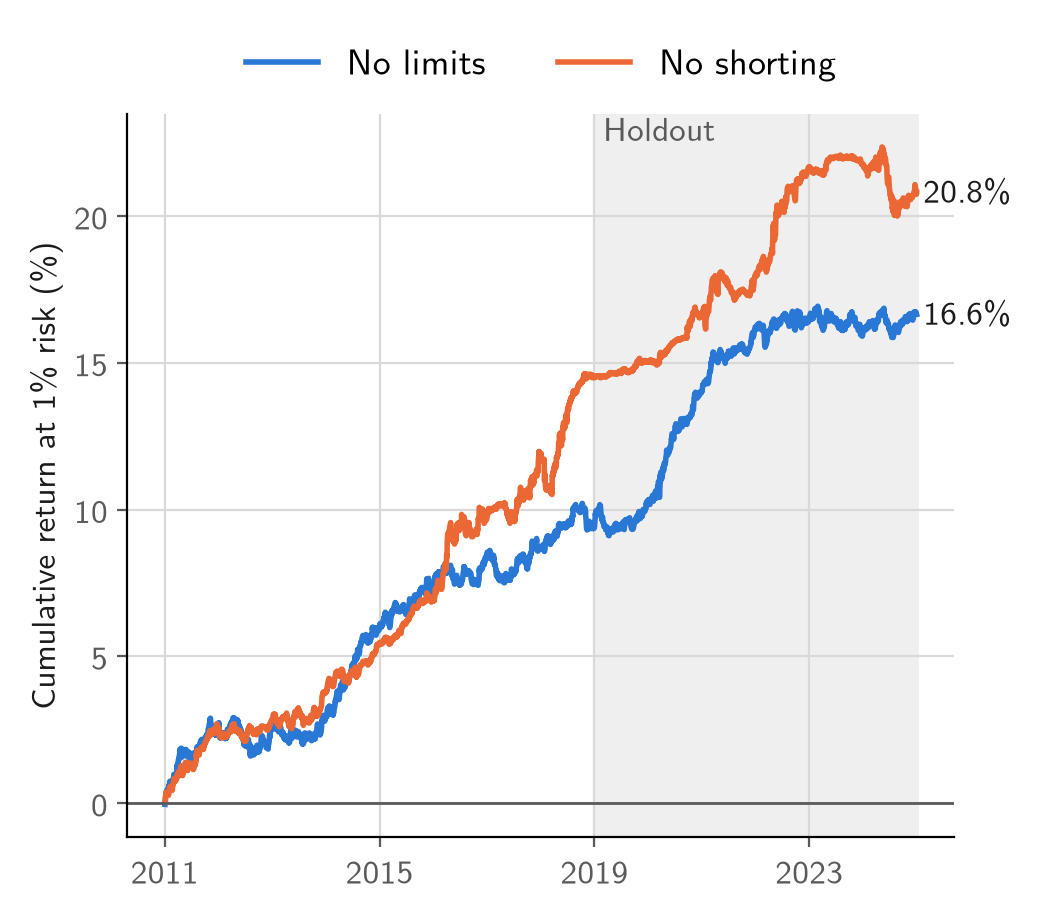

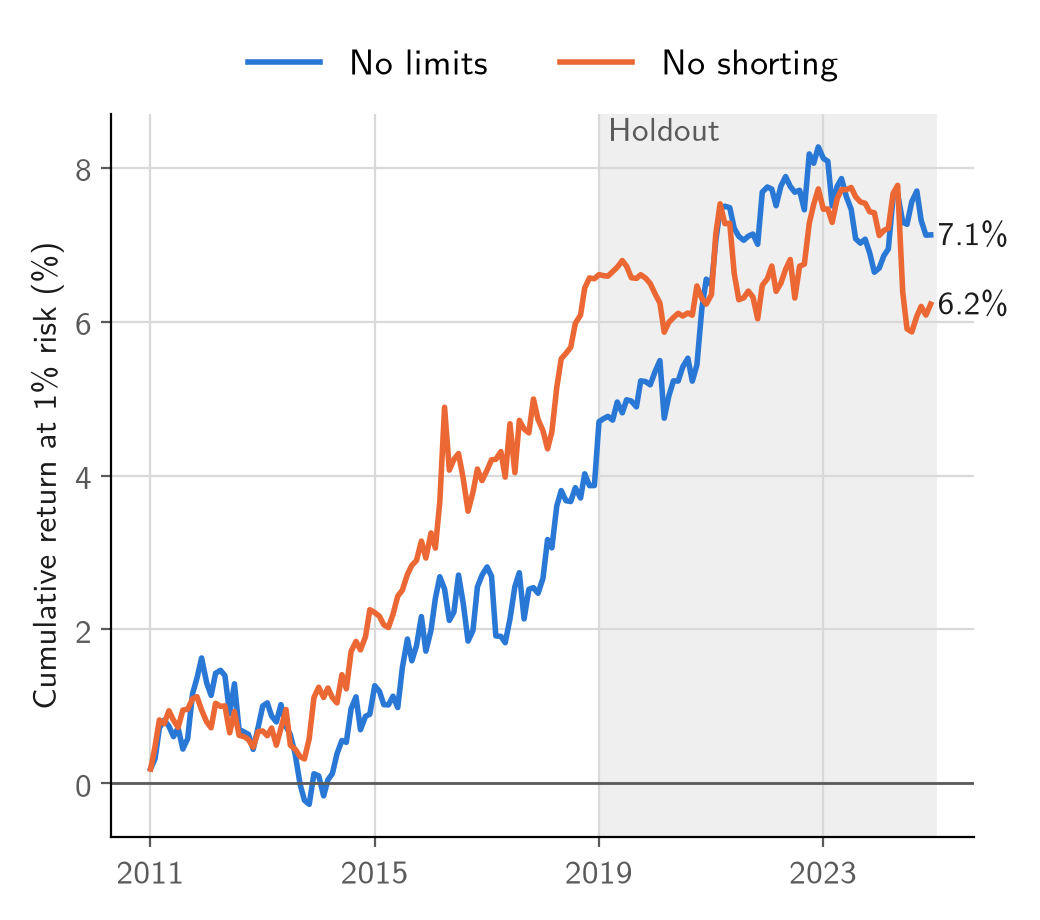

In [23]:
def fig_pair(freq: str):
    """Slide only, no banner: the three runs of one frequency, each scaled to 1% annual realized active risk."""
    r = pl.read_parquet(AN / "return_series.parquet")
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    ax.grid(True, color=style.GRIDLINE, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=style.MUTED_INK, labelsize=12)
    ends = []
    hold = pl.read_parquet(HOLD / "return_series.parquet") if has_holdout() else None
    if hold is not None:
        ax.axvspan(dt.date(2019, 1, 1), hold["date"].max(), color="#efefef", zorder=0)
        ax.text(dt.date(2019, 3, 1), 1, "Holdout", transform=ax.get_xaxis_transform(), va="top", fontsize=12, color=style.MUTED_INK)
    for n, label, color in zip(PAIRS[freq], ROLE, ROLE_COLOR):
        parts = [r.filter(pl.col("run") == n).sort("date").select("date", "net")]
        if hold is not None:
            parts.append(hold.filter(pl.col("run") == n).sort("date").select("date", "net"))
        # each period scaled to 1% of its own realized risk, so neither period dominates the picture
        parts = [p_.with_columns(pl.col("net") * 0.01 / (p_["net"].std() * PER_YEAR[freq] ** 0.5)) for p_ in parts]
        x = pl.concat(parts)
        y = np.cumsum(x["net"].to_numpy()) * 100
        ax.plot(x["date"], y, color=color, linewidth=2.0, label=label)
        ends.append([x["date"][-1], y[-1], y[-1]])
    span = ax.get_ylim()[1] - ax.get_ylim()[0]
    ends.sort(key=lambda e: e[1])
    for a, b in zip(ends, ends[1:]):  # push end labels apart
        b[2] = max(b[2], a[2] + 0.07 * span)
    for d, v, pos in ends:
        ax.text(d + dt.timedelta(days=45), pos, f"{v:.1f}%", va="center", ha="left", fontsize=12, color=style.INK)
    last = 2025 if hold is not None else 2019
    step = 4 if hold is not None else 2
    ax.set_xticks([f"{yr}-01-01" for yr in range(2011, last + 1, step)], [str(yr) for yr in range(2011, last + 1, step)])
    ax.axhline(0, color=style.MUTED_INK, linewidth=1)
    ax.set_ylabel("Cumulative return at 1% risk (%)", fontsize=12, color=style.INK)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False, fontsize=13)
    fig.tight_layout()
    (SLIDES / "figures").mkdir(parents=True, exist_ok=True)
    fig.savefig(SLIDES / "figures" / f"pair_{freq}.png", dpi=200, facecolor="white")
    plt.close(fig)


for freq in ("daily", "monthly"):
    fig_pair(freq)
    display(Image(filename=str(SLIDES / f"figures/pair_{freq}.png"), width=560))

Each period is scaled to 1% risk; shaded years were held back.

- **Daily holds up.** Long-only earns +0.51% a year in 2019–2024 (IR 1.05, t = 2.6); the no-limits IR (1.21) matches 2011–2018.
- **Monthly does not.** A portfolio that trades once a month reaches most events after their strongest weeks.

**Is the optimizer needed?** The simplest long-only use: hold the benchmark, sell every stock with an event in the last 63
days to zero, and give its weight to similar stocks. The run also tested IVOL events; we leave those aside.

In [24]:
assert not HOLDOUT, "development years only"


LO, HI = O["start"], RUN_END


assert HI <= dt.date(2018, 12, 31)


WINDOW, SHARE = 63, 0.05


OUT = OPT / "avoid"


OUT.mkdir(parents=True, exist_ok=True)


start = dt.date(2010, 1, 1)


sm = pl.read_parquet(SMOOTHED, columns=["date", "barrid", "s0"]).filter(pl.col("date").is_between(start, HI))


f = (features(["date", "barrid", "eligible", "market_cap", "ivol63", "s"], years=range(start.year, HI.year + 1))
     .filter(pl.col("date").is_between(start, HI)).collect())


data = sm.join(f.filter(pl.col("eligible")).drop("eligible", "s"), on=["date", "barrid"], how="inner")


days = sorted(data["date"].unique().to_list())


di = {d: i for i, d in enumerate(days)}


kinds = {
    "Liquidity": events(data.select("date", "barrid", "s0", "market_cap"), "s0", SHARE),
    "IVOL": events(data.select("date", "barrid", (-pl.col("ivol63")).alias("nivol"), "market_cap"), "nivol", SHARE),
}


flags = {}


for kind, ev in kinds.items():
    a = ages(data.select("date", "barrid"), ev, di)
    # weights dated D use the signal day D-1: avoided if 1 <= age(D-1) + 1 <= WINDOW
    flags[kind] = a.filter((pl.col("age") + 1).is_between(1, WINDOW)).select(pl.col("date").alias("sig"), "barrid", pl.lit(True).alias("flag"))
    n = ev.filter("event", pl.col("date").is_between(LO, HI)).height
    print(kind, "events per year", round(n / 8, 1), flush=True)


events_per_year = {k: ev.filter("event", pl.col("date").is_between(LO, HI)).height / ((HI - LO).days / 365.25) for k, ev in kinds.items()}


cells = pl.concat([g.with_columns(sig=pl.lit(d)) for d, g in EventAlphas(LO, HI).cells_by_date.items()])


all_days = trading_days(LO - dt.timedelta(days=10), HI)


prev = previous_day(all_days)


daily_dates = [d for d in all_days if LO <= d <= HI]


monthly_dates = [d for k, d in enumerate(daily_dates) if k == 0 or d.month != daily_dates[k - 1].month]


bench = sfd.load_benchmark(LO - dt.timedelta(days=10), HI).select(pl.col("date").alias("sig"), "barrid", pl.col("weight").alias("b"))


def weights(kind: str, dates: list[dt.date]) -> tuple[pl.DataFrame, float]:
    w = (pl.DataFrame({"date": dates, "sig": [prev[d] for d in dates]})
         .join(bench, on="sig")
         .join(flags[kind], on=["sig", "barrid"], how="left").with_columns(pl.col("flag").fill_null(False))
         .join(cells, on=["sig", "barrid"], how="left").with_columns(pl.col("cell").fill_null(25)))
    w = w.with_columns(b=pl.col("b") / pl.col("b").sum().over("date"))  # benchmark weights sum to 1 each day
    w = w.with_columns(
        removed=pl.col("b").filter(pl.col("flag")).sum().over("date", "cell"),
        receivers=pl.col("b").filter(~pl.col("flag")).sum().over("date", "cell"),
    ).with_columns(pl.col("removed").fill_null(0.0), pl.col("receivers").fill_null(0.0))
    # groups with nothing left to receive: their weight goes to the whole benchmark
    w = w.with_columns(leftover=pl.when(pl.col("flag") & (pl.col("receivers") <= 0)).then(pl.col("b")).otherwise(0.0))
    w = w.with_columns(
        leftover_total=pl.col("leftover").sum().over("date"),
        kept_total=pl.col("b").filter(~pl.col("flag")).sum().over("date"),
    ).with_columns(pl.col("leftover_total").fill_null(0.0))
    w = w.with_columns(active_weight=pl.when(pl.col("flag")).then(-pl.col("b")).otherwise(
        pl.when(pl.col("receivers") > 0).then(pl.col("b") * pl.col("removed") / pl.col("receivers")).otherwise(0.0)
        + pl.col("b") * pl.col("leftover_total") / pl.col("kept_total")))
    chk = w.group_by("date").agg(pl.col("active_weight").sum().abs().alias("s"), (pl.col("b") + pl.col("active_weight")).min().alias("m"),
                                 pl.col("b").filter(pl.col("flag")).sum().alias("avoided"))
    assert chk["s"].max() < 1e-9, chk["s"].max()
    assert chk["m"].min() > -1e-12, chk["m"].min()
    return w.select("date", "barrid", "active_weight", "b", "flag"), float(chk["avoided"].fill_null(0.0).mean())


spec = features(["date", "barrid", "s"], years=range(LO.year, HI.year + 1)).filter(pl.col("date").is_between(LO, HI)).collect()


rows, series = [], []


for kind in kinds:
    for frequency, dates in (("daily", daily_dates), ("monthly", monthly_dates)):
        name = f"{kind}, {frequency}"
        w, avoided = weights(kind, dates)
        k = 252 if frequency == "daily" else 12
        g = gross_returns(w.select("date", "barrid", "active_weight"), frequency, HI).sort("date")
        x = g["gross"].to_numpy()
        vol = x.std(ddof=1) * math.sqrt(k)
        ir = x.mean() * k / vol
        cum = np.cumsum(x)
        dd = float((cum - np.maximum.accumulate(np.r_[0.0, cum])[1:]).min())
        by_year = g.group_by(pl.col("date").dt.year()).agg(pl.col("gross").sum())["gross"]
        m = g.join(market_returns(g["date"]), on="date", how="left").drop_nulls("market")
        beta = float(np.cov(m["gross"], m["market"], ddof=1)[0, 1] / np.var(m["market"].to_numpy(), ddof=1))
        hedged = m["gross"].to_numpy() - beta * m["market"].to_numpy()
        # specific-return version: monthly weights held flat through the month
        held = w.select("date", "barrid", "active_weight")
        if frequency == "monthly":
            cal = pl.DataFrame({"day": daily_dates}).join_asof(pl.DataFrame({"date": dates}), left_on="day", right_on="date", strategy="backward")
            held = held.join(cal, on="date").drop("date").rename({"day": "date"})
        sp = held.join(spec, on=["date", "barrid"], how="left").group_by("date").agg((pl.col("active_weight") * pl.col("s").fill_null(0.0)).sum().alias("x")).sort("date")
        sx = sp["x"].to_numpy()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            c = sfp.generate_trading_costs(w.select("date", "barrid", pl.col("active_weight").alias("weight")).sort("date", "barrid"))
        years = (HI - LO).days / 365.25
        rows.append({
            "portfolio": name, "events_per_year": events_per_year[kind], "avoided_benchmark_weight_pct": avoided * 100,
            "active_return_pct": x.mean() * k * 100, "active_risk_pct": vol * 100, "ir": ir, "t": ir * math.sqrt(years),
            "max_drawdown_pct": dd * 100, "positive_years": f"{int((by_year > 0).sum())}/{len(by_year)}",
            "market_beta": beta, "hedged_ir": float(hedged.mean() / hedged.std(ddof=1) * math.sqrt(k)),
            "specific_return_pct": sx.mean() * 252 * 100, "specific_ir": float(sx.mean() / sx.std(ddof=1) * math.sqrt(252)),
            "turnover_per_year": float(c["trade"].abs().sum() / years), "spread_cost_pct_per_year": float(c["cost"].sum() / years * 100),
        })
        series.append(g.select(pl.lit(name).alias("portfolio"), "date", "gross"))
        if frequency == "daily":  # hand check: sum(h x same-day return) on one day matches the sf-quant return
            d0 = dates[100]
            r = sfd.load_assets(d0, d0, ["date", "barrid", "return"], in_universe=False).select("barrid", (pl.col("return") / 100).alias("r"))
            manual = float(w.filter(pl.col("date") == d0).join(r, on="barrid", how="left").select((pl.col("active_weight") * pl.col("r").fill_null(0.0)).sum()).item())
            print(name, "hand check", d0, round(manual * 1e4, 4), "bp vs", round(float(g.filter(pl.col("date") == d0)["gross"].item()) * 1e4, 4), "bp", flush=True)


out = pl.DataFrame(rows)


out.write_csv(OUT / "avoid_summary.csv")


pl.concat(series).write_parquet(OUT / "avoid_returns.parquet")


with pl.Config(tbl_cols=20, tbl_width_chars=250, float_precision=3):
    print(out, flush=True)

Liquidity events per year 1905.0
IVOL events per year 620.2
Liquidity, daily hand check 2011-05-26 -0.612 bp vs -0.612 bp
IVOL, daily hand check 2011-05-26 -0.0299 bp vs -0.0299 bp
shape: (4, 15)
┌───────────────────┬─────────────────┬───────────────────┬───────────────────┬─────────────────┬────────┬────────┬──────────────────┬────────────────┬─────────────┬───────────┬───────────────────┬─────────────┬───────────────────┬──────────────────┐
│ portfolio         ┆ events_per_year ┆ avoided_benchmark ┆ active_return_pct ┆ active_risk_pct ┆ ir     ┆ t      ┆ max_drawdown_pct ┆ positive_years ┆ market_beta ┆ hedged_ir ┆ specific_return_p ┆ specific_ir ┆ turnover_per_year ┆ spread_cost_pct_ │
│ ---               ┆ ---             ┆ _weight_pct       ┆ ---               ┆ ---             ┆ ---    ┆ ---    ┆ ---              ┆ ---            ┆ ---         ┆ ---       ┆ ct                ┆ ---         ┆ ---               ┆ per_year         │
│ str               ┆ f64             ┆ ---        

In [25]:
avoid = pl.read_csv(OPT / "avoid/avoid_summary.csv").filter(pl.col("portfolio").str.starts_with("Liquidity"))
display(avoid.select("portfolio", pl.col("active_return_pct").alias("return, %/yr"), pl.col("active_risk_pct").alias("risk, %"), "ir", "t"))

portfolio,"return, %/yr","risk, %",ir,t
"""Liquidity, daily""",0.05,0.47,0.11,0.30
"""Liquidity, monthly""",0.10,0.43,0.23,0.66


Avoiding flagged stocks earns almost nothing: dropping them tilts the portfolio toward large stocks, and that noise swamps the effect. The optimizer hedges it.

## 8. How much to trust it

- **One honest test.** The design was refined on 2011–2018 in four rounds (below), then frozen; 2019–2024 was run once.
- **Small.** After bid–ask spreads (0.19% a year), daily long-only earns about +0.3% a year.
- **Short sample.** An IR's standard error is about $1/\sqrt{\text{years}}$, so six years leaves the true long-only IR between
  roughly 0.2 and 1.9.

**What changed, and when** (daily runs, 2011–2018; version 1's result is from its own summary):

In [26]:
versions = {"2. event clock": "v2_event_clock/analysis", "3. no positive alpha, hedge with similar stocks": "v3_event_clock/analysis",
            "4. alpha scaled by volatility (final)": "analysis"}
get = lambda f, run, col: f.filter(pl.col("run") == run)[col].item()
table = [{"version": "1. flag that turns over daily", "no limits, %/yr": -0.9, "no limits IR": -0.15, "no shorting, %/yr": None, "no shorting IR": None}]
for v, d in versions.items():
    f = pl.read_csv(OPT / d / "summary.csv")
    table.append({"version": v, "no limits, %/yr": get(f, "U-D", "net_return") * 100, "no limits IR": get(f, "U-D", "ir"),
                  "no shorting, %/yr": get(f, "C-D", "net_return") * 100, "no shorting IR": get(f, "C-D", "ir")})
display(pl.DataFrame(table))

version,"no limits, %/yr",no limits IR,"no shorting, %/yr",no shorting IR
"""1. flag that turns over daily""",-0.90,-0.15,null,null
"""2. event clock""",-2.77,-0.49,-0.12,-0.24
"""3. no positive alpha, hedge wi…",3.23,0.58,0.36,1.48
"""4. alpha scaled by volatility …",6.84,1.17,0.19,1.82


**Why the 2019–2024 long-only portfolio is bigger.** Until 2015 the model gave large stocks no alpha, so it could only sell small stocks with little benchmark weight; later, large stocks got a negative alpha too:

In [27]:
rows = []
for folder, params_file, years in ((AN, OPT / "event_params.json", range(2011, 2019)),
                                   (HOLD, ROOT / "output/optimizer_holdout/event_params.json", range(2019, 2025))):
    p = json.loads(params_file.read_text())
    r = pl.read_parquet(folder / "return_series.parquet").filter(pl.col("run") == "C-D")
    for (year,), g in r.group_by(pl.col("date").dt.year()):
        if year in years:
            rows.append({"year": year, "large-stock alpha": p[str(year)]["rates"]["large"][0] * 1e4,
                         "long-only risk, %": g["net"].std() * 252 ** 0.5 * 100, "long-only return, %": g["net"].sum() * 100})
display(pl.DataFrame(rows).sort("year"))

year,large-stock alpha,"long-only risk, %","long-only return, %"
2011,0.00,0.08,0.25
2012,0.00,0.06,0.04
2013,0.00,0.08,0.10
2014,-0.08,0.07,0.17
2015,0.00,0.05,0.16
…,…,…,…
2020,-5.00,0.30,0.76
2021,-7.21,0.59,0.63
2022,-7.10,0.68,1.80
2023,-7.35,0.21,0.06


## 9. Conclusion

Stocks whose trading dries up keep falling for months: most investors no longer want them, and the hand-off to the few patient
buyers is slow. A long-only fund can harvest this,
but only with a volatility-scaled Grinold–Kahn alpha, the optimizer and daily trading. The gain is a few tenths of a percent a
year, so we recommend it as one input to the fund's combined alpha.